# | Machine Learning |
<a id="secao-01"></a>

## Eduardo Braz de Oliveira

**Professor:** Arthur Schneider Figueira  
**Tipo de problema:** Classificação binária  
**Tema:** Previsão de cancelamento de clientes (Customer Churn)

---

<a id="secao-02"></a>

## Problema de negócio

O projeto utiliza dados de clientes de uma empresa de telecomunicações para identificar padrões associados ao **cancelamento do serviço (churn)**.

Cada linha da base representa um cliente e reúne informações sobre:
- perfil do cliente;
- tempo de relacionamento com a empresa;
- serviços contratados;
- tipo de contrato;
- forma de pagamento;
- valores cobrados.

A variável-alvo é **`Churn`**:

- `Churn = No` → o cliente permaneceu na empresa;
- `Churn = Yes` → o cliente cancelou/deixou a empresa.

Trata-se de um problema de **classificação binária**, pois o objetivo é classificar cada cliente em uma de duas classes: **cancelou** ou **não cancelou**.

### Quem pode se beneficiar?

As áreas de **retenção, CRM, marketing, relacionamento e atendimento** podem utilizar esse tipo de modelo para identificar clientes com maior risco de cancelamento e direcionar ações preventivas, como ofertas personalizadas, alteração de planos, contato proativo ou campanhas de fidelização.

### Base selecionada

Foi utilizada a base pública **Telco Customer Churn**, disponibilizada no Kaggle por **BlastChar** e baseada no conjunto de exemplo da IBM.

- **7.043 registros**
- **21 colunas originais**
- variáveis numéricas e categóricas
- variável-alvo: `Churn`

**Fonte:** Kaggle — Telco Customer Churn  
`https://www.kaggle.com/datasets/blastchar/telco-customer-churn`

## Índice geral

Clique no título para navegar. A localização conta todas as células do arquivo, incluindo texto e código; não corresponde ao número de execução. Incluem-se os títulos principais e as duas subseções indicadas para consulta.

| Título | Localização |
|---|---|
| [1. Bibliotecas](#secao-03) | Célula 3 |
| [1.1 Ambiente de execução e versões das bibliotecas](#ambiente-versoes) | Célula 5 |
| [2. Carregamento da base](#secao-04) | Célula 7 |
| [2.1 Dicionário das variáveis originais](#dicionario-variaveis) | Célula 10 |
| [3. Exploração](#secao-05) | Célula 11 |
| [4. Dados faltantes, valores em branco e duplicidades](#secao-06) | Célula 15 |
| [5. Remoção da coluna de identificação](#secao-07) | Célula 18 |
| [6. Análise de outliers](#secao-08) | Célula 20 |
| [7. Engenharia de variáveis](#secao-09) | Célula 23 |
| [8. Conversão da variável-alvo](#secao-10) | Célula 26 |
| [Atividade 1 - Análise exploratória de churn por categorias e faixas numéricas](#secao-11) | Célula 28 |
| [Síntese da análise exploratória](#sintese-exploratoria) | Célula 30 |
| [9. Separação entre variáveis explicativas e alvo](#secao-12) | Célula 32 |
| [10. Conversão das variáveis textuais e escalonamento](#secao-13) | Célula 35 |
| [Atividade 2 - Tratamento do desbalanceamento com class_weight](#secao-14) | Célula 42 |
| [Atividade 3 - GridSearchCV e avaliação de sobreajuste](#secao-15) | Célula 43 |
| [Atividade 4 - Comparação de métricas e seleção por métrica balanceada](#secao-16) | Célula 46 |
| [12. Seleção do modelo final](#secao-17) | Célula 50 |
| [13. Matrizes de confusão dos modelos com e sem ponderação](#secao-18) | Célula 52 |
| [14. Variáveis utilizadas pelo modelo selecionado](#secao-19) | Célula 55 |
| [15. Resumo dos tratamentos realizados](#secao-20) | Célula 57 |
| [16. Conclusão](#secao-21) | Célula 58 |
| [17. Da atividade](#secao-22) | Célula 59 |

As Atividades 2 e 3 compartilham o experimento de treinamento. A Atividade 4 apresenta a avaliação e a seleção a partir dos resultados desse experimento. O conteúdo da antiga seção 11 está distribuído entre as Atividades 2 e 3; manteve-se a numeração das seções posteriores.



<a id="secao-03"></a>

## 1. Bibliotecas

Serão utilizadas bibliotecas para:
- manipulação dos dados;
- visualização;
- pré-processamento;
- escalonamento;
- treinamento dos quatro algoritmos exigidos;
- avaliação dos modelos.


In [1]:
import kagglehub

import warnings


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import balanced_accuracy_score
from IPython.display import display, Markdown

C:\Users\eduar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<a id="ambiente-versoes"></a>

### 1.1 Ambiente de execução e versões das bibliotecas

Esta seção registra o ambiente efetivamente utilizado pelo kernel do notebook. As versões são consultadas automaticamente, evitando depender de números digitados manualmente. Para reproduzir o experimento, recomenda-se utilizar a mesma versão do Python e instalar as dependências registradas em um ambiente virtual.

A célula abaixo mostra as versões e grava `requirements.txt` e `ambiente_execucao.json` na pasta `ambiente_reprodutibilidade`, dentro do diretório de trabalho do kernel. Ela pode ser executada novamente para atualizar esses arquivos; o caminho absoluto é exibido para facilitar sua localização.

O arquivo requirements registra as dependências diretas utilizadas no notebook, incluindo o kernel Jupyter. Não representa um bloqueio de todas as dependências transitivas. O registro do ambiente melhora a reprodutibilidade, mas não garante resultados idênticos entre plataformas ou versões diferentes da base.


In [2]:
# Registro do ambiente do kernel; não utiliza credenciais nem variáveis de ambiente.
import sys
import platform
import json
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError

packages = ['numpy', 'pandas', 'scikit-learn', 'matplotlib',
            'kagglehub', 'ipython', 'ipykernel']
versions = {}
missing = []
for package in packages:
    try:
        versions[package] = version(package)
    except PackageNotFoundError:
        missing.append(package)

if missing:
    raise RuntimeError('Não foi possível registrar: ' + ', '.join(missing))

environment = {
    'python': platform.python_version(),
    'python_implementation': platform.python_implementation(),
    'system': platform.system(),
    'machine': platform.machine(),
    'recorded_at_utc': datetime.now(timezone.utc).isoformat(),
    'packages': versions,
    'dataset': 'blastchar/telco-customer-churn',
    'scope': 'Ambiente do kernel no momento do registro; dependências diretas.'
}
print('Python:', environment['python'])
print('Sistema:', environment['system'], '| Arquitetura:', environment['machine'])
display(pd.DataFrame(versions.items(), columns=['Biblioteca', 'Versão']))

environment_dir = Path.cwd() / 'ambiente_reprodutibilidade'
environment_dir.mkdir(exist_ok=True)
requirements = '# Python ' + environment['python'] + '\n'
requirements += '# Dependências diretas registradas pelo kernel do notebook.\n'
requirements += '\n'.join(f'{name}=={value}' for name, value in versions.items()) + '\n'
(environment_dir / 'requirements.txt').write_text(requirements, encoding='utf-8')
(environment_dir / 'ambiente_execucao.json').write_text(
    json.dumps(environment, ensure_ascii=False, indent=2), encoding='utf-8')
print('Arquivos de reprodutibilidade salvos em:', environment_dir.resolve())


Python: 3.11.9
Sistema: Windows | Arquitetura: AMD64


,Biblioteca,Versão
0,numpy,2.3.3
1,pandas,3.0.1
2,scikit-learn,1.8.0
3,matplotlib,3.10.6
4,kagglehub,1.0.2
5,ipython,9.7.0
6,ipykernel,7.1.0


Arquivos de reprodutibilidade salvos em: C:\Users\eduar\Scripts\Machine Learning\ambiente_reprodutibilidade


<a id="secao-04"></a>

## 2. Carregamento da base

A base foi obtida diretamente do **Kaggle**, utilizando o pacote `kagglehub`.

Dataset utilizado:

`blastchar/telco-customer-churn`

Arquivo:

`WA_Fn-UseC_-Telco-Customer-Churn.csv`

Essa forma de carregamento deixa a origem da base rastreável e reproduzível.

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [4]:

# Download da base
path = kagglehub.dataset_download(
    "blastchar/telco-customer-churn"
)

# Carregamento do arquivo CSV
df = pd.read_csv(
    path + "/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print(f"Linhas: {df.shape[0]:,}")
print(f"Colunas: {df.shape[1]}")

display(df.head())


Linhas: 7,043
Colunas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


<a id="dicionario-variaveis"></a>

### 2.1 Dicionário das variáveis originais



| Coluna | Significado no negócio |
|---|---|
| `customerID` | Identificador único do cliente |
| `gender` | Sexo cadastrado do cliente |
| `SeniorCitizen` | Indica se o cliente é idoso (`1 = sim`, `0 = não`) |
| `Partner` | Indica se possui parceiro/cônjuge |
| `Dependents` | Indica se possui dependentes |
| `tenure` | Quantidade de meses em que o cliente permaneceu na empresa |
| `PhoneService` | Possui serviço de telefonia |
| `MultipleLines` | Possui múltiplas linhas telefônicas |
| `InternetService` | Tipo de internet: DSL, fibra óptica ou nenhuma |
| `OnlineSecurity` | Possui serviço de segurança online |
| `OnlineBackup` | Possui serviço de backup online |
| `DeviceProtection` | Possui proteção de dispositivo |
| `TechSupport` | Possui suporte técnico |
| `StreamingTV` | Possui serviço de streaming de TV |
| `StreamingMovies` | Possui serviço de streaming de filmes |
| `Contract` | Tipo de contrato: mensal, 1 ano ou 2 anos |
| `PaperlessBilling` | Utiliza cobrança sem papel |
| `PaymentMethod` | Método de pagamento |
| `MonthlyCharges` | Valor cobrado mensalmente |
| `TotalCharges` | Total acumulado de cobranças durante o relacionamento |
| `Churn` | Indica se o cliente cancelou (`Yes`) ou permaneceu (`No`) |

### Por que essa base é adequada?

Ela permite relacionar **perfil, serviços, contrato, pagamento e histórico financeiro** com um resultado de negócio claramente definido: **cancelamento de clientes**.


<a id="secao-05"></a>

## 3. Exploração

Nesta etapa serão avaliados:
- dimensão da base;
- tipos das variáveis;
- estatísticas descritivas;
- quantidade de valores únicos;
- distribuição da variável-alvo.


In [5]:

print("Dimensão da base:", df.shape)
print("\nTipos das colunas:")
display(df.dtypes.to_frame("tipo"))

print("\nEstatísticas das variáveis numéricas:")
display(df.describe(include=[np.number]).T)

print("\nQuantidade de valores únicos por coluna:")
display(df.nunique().sort_values().to_frame("valores_unicos"))


Dimensão da base: (7043, 21)

Tipos das colunas:


,tipo
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str



Estatísticas das variáveis numéricas:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0000,0.1621,0.3686,0.0000,0.0000,0.0000,0.0000,1.0000
tenure,7043.0000,32.3711,24.5595,0.0000,9.0000,29.0000,55.0000,72.0000
MonthlyCharges,7043.0000,64.7617,30.0900,18.2500,35.5000,70.3500,89.8500,118.7500



Quantidade de valores únicos por coluna:


,valores_unicos
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
PhoneService,2
PaperlessBilling,2
Churn,2
MultipleLines,3
TechSupport,3
StreamingTV,3


,Quantidade,Percentual (%)
Churn,,
No,5174,73.4630
Yes,1869,26.5370


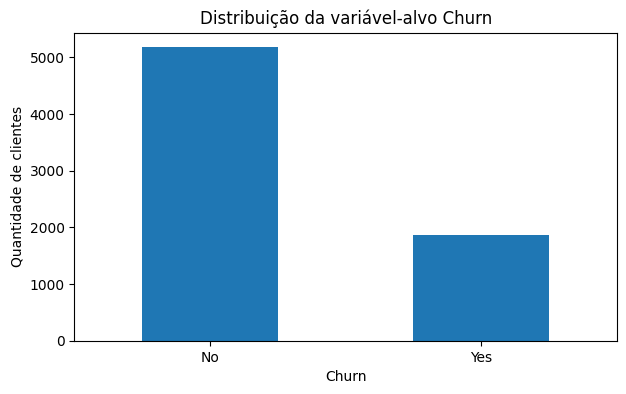

In [6]:

target_counts = df["Churn"].value_counts()
target_pct = df["Churn"].value_counts(normalize=True).mul(100)

distribuicao_alvo = pd.DataFrame({
    "Quantidade": target_counts,
    "Percentual (%)": target_pct
})

display(distribuicao_alvo)

ax = distribuicao_alvo["Quantidade"].plot(
    kind="bar",
    figsize=(7, 4),
    title="Distribuição da variável-alvo Churn"
)
ax.set_xlabel("Churn")
ax.set_ylabel("Quantidade de clientes")
plt.xticks(rotation=0)
plt.show()


### Leitura da variável-alvo

Na execução da base:

- **5.174 clientes (73,46%)** não cancelaram;
- **1.869 clientes (26,54%)** cancelaram.

A classe de churn é minoritária. Por isso, a análise não deve depender apenas de **Accuracy**; também é importante observar **Precision, Recall e F1-score** da classe `Churn = 1`.


<a id="secao-06"></a>

## 4. Dados faltantes, valores em branco e duplicidades

A coluna `TotalCharges` pode conter valores em branco armazenados como texto.  
Por isso, ela será convertida para numérica utilizando `errors='coerce'`, transformando valores inválidos em `NaN`.

Para clientes com `tenure = 0`, um `TotalCharges` ausente é coerente com um cliente recém-chegado. Nesses casos, será atribuído valor **0**.

Caso permaneçam valores numéricos faltantes, o pipeline dos modelos utilizará a **mediana**. Para variáveis categóricas, será usada a categoria **mais frequente**.


In [7]:

df = df.copy()

# Remoção de espaços extras de colunas textuais
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# TotalCharges deve ser numérica
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing antes do tratamento específico:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))

# Clientes novos (tenure = 0) ainda não acumularam cobrança total
mask_new_customer = df["TotalCharges"].isna() & (df["tenure"] == 0)
df.loc[mask_new_customer, "TotalCharges"] = 0

print(f"TotalCharges preenchido com zero para clientes com tenure = 0: {mask_new_customer.sum()} registros")

print("\nMissing após esse tratamento:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))

print("\nLinhas duplicadas:", df.duplicated().sum())
print("customerID duplicados:", df["customerID"].duplicated().sum())


Missing antes do tratamento específico:


C:\Users\eduar\AppData\Local\Temp\ipykernel_36688\3462668434.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


,missing
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


TotalCharges preenchido com zero para clientes com tenure = 0: 11 registros

Missing após esse tratamento:


,missing
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Linhas duplicadas: 0
customerID duplicados: 0


### Resposta ao critério — missing e duplicidades

A análise encontrou:

- **11 valores ausentes em `TotalCharges`**;
- **0 valores ausentes** nas demais colunas;
- **0 linhas duplicadas**;
- **0 `customerID` duplicados**.

Os 11 registros com `TotalCharges` ausente correspondiam a clientes com **`tenure = 0`**, ou seja, clientes recém-chegados e ainda sem cobrança acumulada. Por isso, esses valores foram preenchidos com **0**.

Após o tratamento, a base ficou com **0 valores ausentes**.


<a id="secao-07"></a>

## 5. Remoção da coluna de identificação

`customerID` identifica individualmente cada cliente, mas não representa uma característica comportamental ou cadastral útil para generalização do modelo.

Conforme a orientação da atividade, a coluna de ID será removida.


In [8]:

df = df.drop(columns=["customerID"])
print("Dimensão após remover customerID:", df.shape)


Dimensão após remover customerID: (7043, 20)



<a id="secao-08"></a>

## 6. Análise de outliers

Será utilizado o método **IQR (Intervalo Interquartil)** para identificar valores potencialmente extremos nas variáveis numéricas.

Os valores serão analisados, mas **não serão removidos automaticamente**. Em uma base de telecomunicações, valores altos de tempo de permanência ou cobrança podem representar clientes reais e relevantes. Removê-los apenas por uma regra estatística poderia eliminar informação válida.


,Variável,Limite inferior,Limite superior,Qtde. outliers pelo IQR
0,tenure,-60.0000,124.0000,0
1,MonthlyCharges,-46.0250,171.3750,0
2,TotalCharges,-4683.5250,8868.6750,0


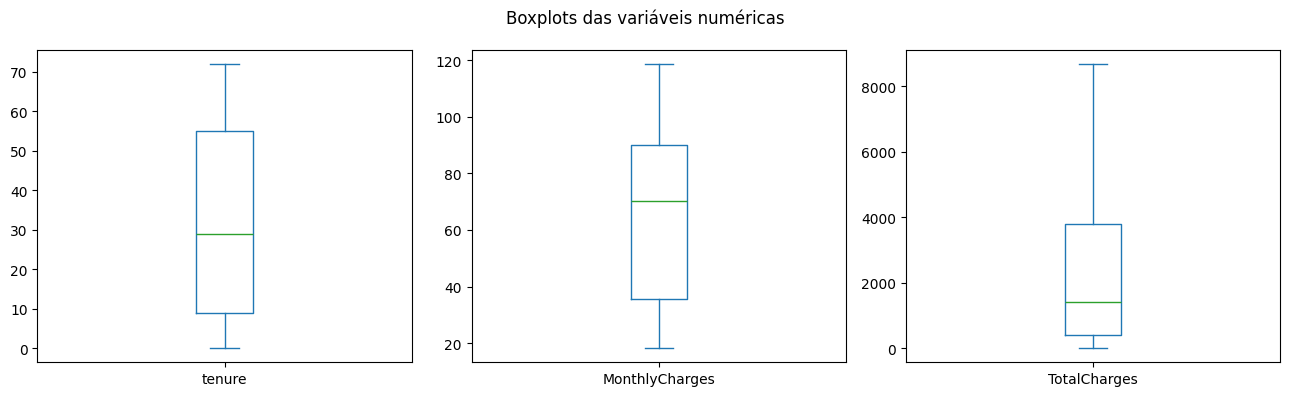

In [9]:

numeric_for_outliers = ["tenure", "MonthlyCharges", "TotalCharges"]

outlier_summary = []

for col in numeric_for_outliers:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "Variável": col,
        "Limite inferior": lower,
        "Limite superior": upper,
        "Qtde. outliers pelo IQR": outliers
    })

display(pd.DataFrame(outlier_summary))

df[numeric_for_outliers].plot(
    kind="box",
    subplots=True,
    layout=(1, 3),
    figsize=(13, 4),
    title="Boxplots das variáveis numéricas"
)
plt.tight_layout()
plt.show()


### Resultado da análise de outliers

Pelo método **IQR (1,5 × intervalo interquartil)**, **não foram identificados outliers** nas três variáveis numéricas analisadas:

- `tenure`: 0 outliers;
- `MonthlyCharges`: 0 outliers;
- `TotalCharges`: 0 outliers.

Portanto, **não foi necessária remoção ou substituição de registros por outliers**.

Essa conclusão é baseada diretamente nos limites calculados na célula anterior.


<a id="secao-09"></a>

## 7. Engenharia de variáveis

Foram testadas/criadas variáveis derivadas para representar melhor o comportamento do cliente:

1. **`NumServices`**: quantidade de serviços adicionais contratados;
2. **`TenureGroup`**: faixa de tempo de relacionamento com a empresa;
3. **`AutomaticPayment`**: identifica se o cliente utiliza forma de pagamento automática;
4. **`AvgMonthlySpend`**: média aproximada do gasto mensal acumulado (`TotalCharges / tenure`).

Essas variáveis são criadas apenas a partir de informações já disponíveis na base e serão utilizadas em conjunto com as variáveis originais.


In [10]:

service_cols = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["NumServices"] = sum(df[col].eq("Yes").astype(int) for col in service_cols)

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 meses", "13-24 meses", "25-48 meses", "49-72 meses"]
)

df["AutomaticPayment"] = np.where(
    df["PaymentMethod"].str.contains("automatic", case=False, na=False),
    "Yes",
    "No"
)

df["AvgMonthlySpend"] = np.where(
    df["tenure"] > 0,
    df["TotalCharges"] / df["tenure"],
    df["MonthlyCharges"]
)

display(
    df[[
        "tenure", "TotalCharges", "MonthlyCharges",
        "NumServices", "TenureGroup",
        "AutomaticPayment", "AvgMonthlySpend"
    ]].head(10)
)


,tenure,TotalCharges,MonthlyCharges,NumServices,TenureGroup,AutomaticPayment,AvgMonthlySpend
0,1,29.8500,29.8500,1,0-12 meses,No,29.8500
1,34,1889.5000,56.9500,3,25-48 meses,No,55.5735
2,2,108.1500,53.8500,3,0-12 meses,No,54.0750
3,45,1840.7500,42.3000,3,25-48 meses,Yes,40.9056
4,2,151.6500,70.7000,1,0-12 meses,No,75.8250
5,8,820.5000,99.6500,5,0-12 meses,No,102.5625
6,22,1949.4000,89.1000,4,13-24 meses,Yes,88.6091
7,10,301.9000,29.7500,1,0-12 meses,No,30.1900
8,28,3046.0500,104.8000,6,25-48 meses,No,108.7875
9,62,3487.9500,56.1500,3,49-72 meses,Yes,56.2573


### Resposta ao critério — engenharia de variáveis

Foram criados quatro novos atributos:

| Nova variável | Construção | Intenção |
|---|---|---|
| `NumServices` | Soma dos serviços contratados | Representar o nível de concentração de serviços do cliente |
| `TenureGroup` | Faixas de tempo de relacionamento | Representar estágio/maturidade do relacionamento |
| `AutomaticPayment` | Derivada de `PaymentMethod` | Identificar clientes com pagamento automático |
| `AvgMonthlySpend` | `TotalCharges / tenure` | Representar o gasto médio mensal histórico |

As técnicas de engenharia de variáveis testadas consistiram na **agregação de informações, discretização de variável contínua em faixas, criação de indicador binário e criação de uma razão entre variáveis existentes.** Os quatro novos atributos foram posteriormente utilizados juntamente com as variáveis originais no treinamento dos algoritmos.


<a id="secao-10"></a>

## 8. Conversão da variável-alvo

A variável `Churn` será convertida para:

- `Yes` → **1**
- `No` → **0**

O valor 1 representa o evento que queremos detectar: **cancelamento**.


In [11]:

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print(df["Churn"].value_counts())
print("\nPercentual:")
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))


Churn
0    5174
1    1869
Name: count, dtype: int64

Percentual:
Churn
0   73.4600
1   26.5400
Name: proportion, dtype: float64


<a id="secao-11"></a>

## Atividade 1 - Análise exploratória de churn por categorias e faixas numéricas

Variáveis numéricas com mais de dez valores distintos são segmentadas em seis intervalos de igual amplitude. Categorias e indicadores são mantidos. Apresentam-se tamanho dos grupos, cancelamentos, taxa de churn e diferença para a média global. Intervalos vazios não geram estimativas. A análise da base completa atende à solicitação descritiva; decisões preditivas são avaliadas no treino.

**Melhoria solicitada:** segmentar variáveis numéricas de alta cardinalidade em 5–10 faixas e analisar a média de churn de cada categoria ou faixa em relação à média global. As tabelas, gráficos e interpretações seguintes apresentam essa evidência.

### Justificativa da segmentação das variáveis numéricas

Foram utilizados seis intervalos de igual amplitude, atendendo à orientação de segmentar as variáveis numéricas em cinco a dez faixas. Essa escolha permite comparar a taxa de churn entre intervalos expressos nas unidades originais das variáveis, como meses de permanência e valores de cobrança, facilitando a interpretação dos resultados.

Os intervalos não possuem necessariamente a mesma quantidade de clientes. Por esse motivo, as tabelas apresentam também o número de observações de cada grupo. Nas quatro variáveis segmentadas, todas as faixas apresentaram mais de 250 registros, permitindo uma descrição apoiada em grupos com volume relevante, embora isso não constitua um teste de significância estatística.

A segmentação possui finalidade exploratória: identificar grupos com taxas de churn superiores ou inferiores à média global de 26,54%. As seis faixas não substituem automaticamente as variáveis utilizadas pelos modelos. O atributo `TenureGroup`, com quatro categorias previamente definidas, constitui uma transformação distinta, utilizada no treinamento e avaliada em conjunto com os demais atributos derivados.

### Como interpretar a referência de 26,54%

Nos gráficos, a linha horizontal vermelha representa a **taxa global de churn da base**, calculada como **1.869 ÷ 7.043 × 100 = 26,54%**. Por isso, a referência é repetida nos gráficos de todas as variáveis. A legenda “Média” da primeira série de gráficos se refere a essa taxa global.

**Cada barra representa a taxa do próprio grupo**, calculada como cancelamentos do grupo divididos pelo número de clientes do grupo. Por exemplo, na faixa de até 12 meses, **1.037 ÷ 2.186 × 100 = 47,44%**; entre 61 e 72 meses, **93 ÷ 1.407 × 100 = 6,61%**.

A coluna `Taxa` é apresentada como proporção: `0,4744` corresponde a **47,44%**. Já a coluna `Diferença (p.p.)` compara cada taxa com a referência global: **47,44% − 26,54% ≈ +20,90 pontos percentuais**.

Ao reunir todos os grupos de uma variável, a média das taxas **ponderada pelo número de clientes de cada grupo** retorna à taxa global de 26,54%, pois são os mesmos clientes distribuídos em grupos diferentes. Isso não implica taxas iguais entre os grupos nem corresponde necessariamente à média aritmética simples das taxas.


,Valores distintos após limpeza
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3
OnlineBackup,3


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,Female,3488,939,0.2692,gender,0.3839
1,Male,3555,930,0.2616,gender,-0.3766


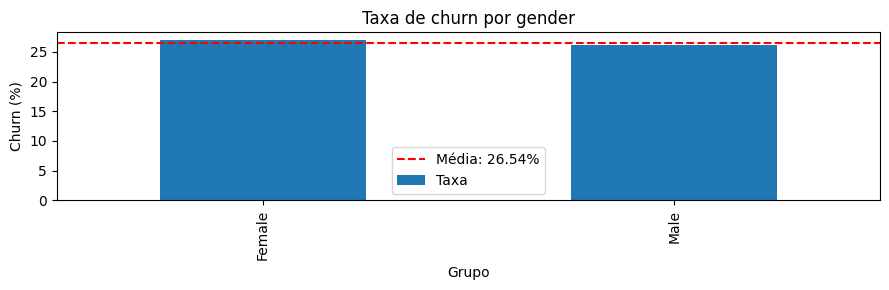

Entre grupos com ao menos 30 clientes, maior taxa: Female (26.92%); menor: Male (26.16%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,0,5901,1393,0.2361,SeniorCitizen,-2.9308
1,1,1142,476,0.4168,SeniorCitizen,15.1443


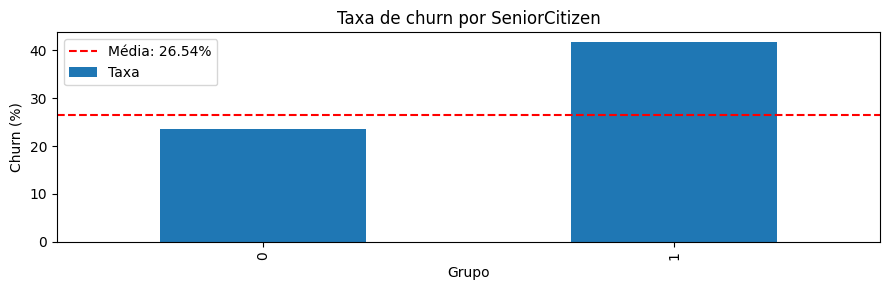

Entre grupos com ao menos 30 clientes, maior taxa: 1 (41.68%); menor: 0 (23.61%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,3641,1200,0.3296,Partner,6.4210
1,Yes,3402,669,0.1966,Partner,-6.8721


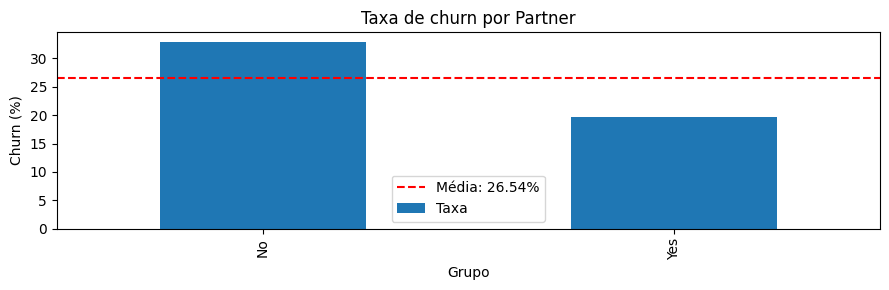

Entre grupos com ao menos 30 clientes, maior taxa: No (32.96%); menor: Yes (19.66%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,4933,1543,0.3128,Dependents,4.7422
1,Yes,2110,326,0.1545,Dependents,-11.0868


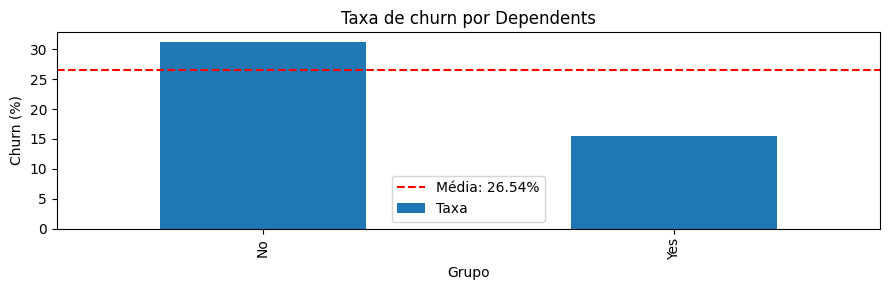

Entre grupos com ao menos 30 clientes, maior taxa: No (31.28%); menor: Yes (15.45%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,"(-0.073, 12.0]",2186,1037,0.4744,tenure,20.9013
1,"(12.0, 24.0]",1024,294,0.2871,tenure,2.1740
2,"(24.0, 36.0]",832,180,0.2163,tenure,-4.9024
3,"(36.0, 48.0]",762,145,0.1903,tenure,-7.5081
4,"(48.0, 60.0]",832,120,0.1442,tenure,-12.1139
5,"(60.0, 72.0]",1407,93,0.0661,tenure,-19.9272


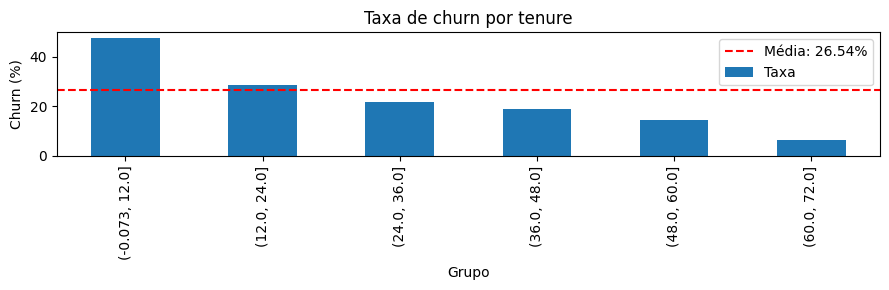

Entre grupos com ao menos 30 clientes, maior taxa: (-0.073, 12.0] (47.44%); menor: (60.0, 72.0] (6.61%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,682,170,0.2493,PhoneService,-1.6103
1,Yes,6361,1699,0.2671,PhoneService,0.1726


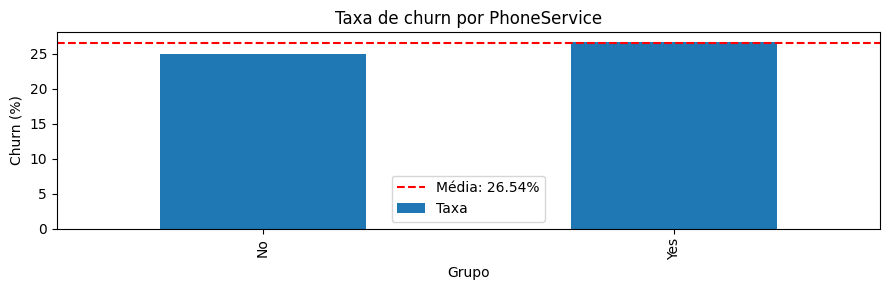

Entre grupos com ao menos 30 clientes, maior taxa: Yes (26.71%); menor: No (24.93%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,3390,849,0.2504,MultipleLines,-1.4927
1,No phone service,682,170,0.2493,MultipleLines,-1.6103
2,Yes,2971,850,0.2861,MultipleLines,2.0729


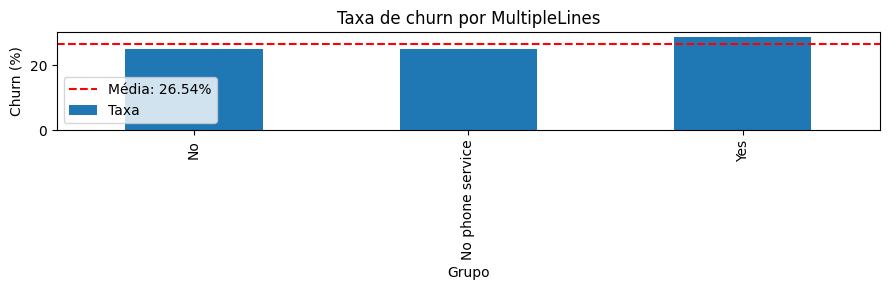

Entre grupos com ao menos 30 clientes, maior taxa: Yes (28.61%); menor: No phone service (24.93%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,DSL,2421,459,0.1896,InternetService,-7.5779
1,Fiber optic,3096,1297,0.4189,InternetService,15.3558
2,No,1526,113,0.0740,InternetService,-19.1320


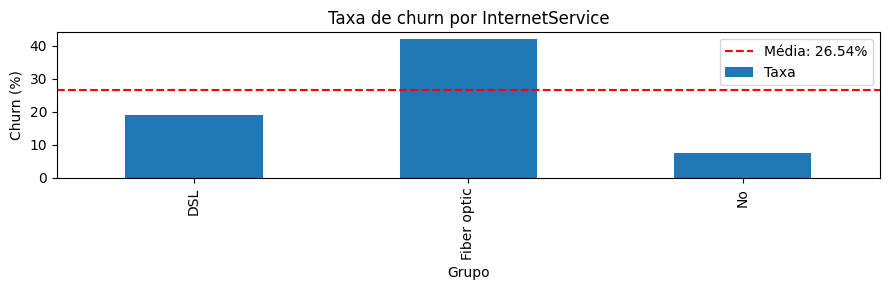

Entre grupos com ao menos 30 clientes, maior taxa: Fiber optic (41.89%); menor: No (7.40%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,3498,1461,0.4177,OnlineSecurity,15.2297
1,No internet service,1526,113,0.0740,OnlineSecurity,-19.1320
2,Yes,2019,295,0.1461,OnlineSecurity,-11.9258


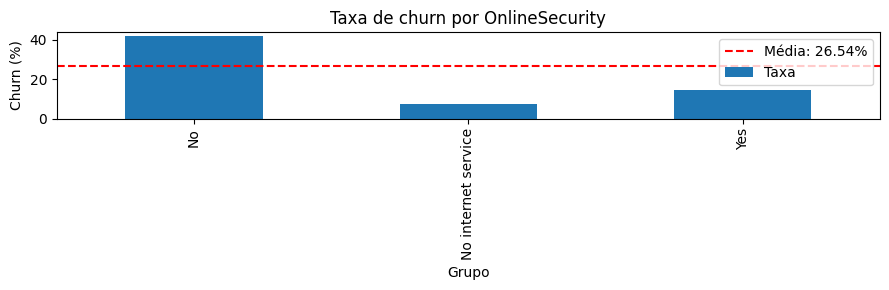

Entre grupos com ao menos 30 clientes, maior taxa: No (41.77%); menor: No internet service (7.40%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,3088,1233,0.3993,OnlineBackup,13.3918
1,No internet service,1526,113,0.0740,OnlineBackup,-19.1320
2,Yes,2429,523,0.2153,OnlineBackup,-5.0055


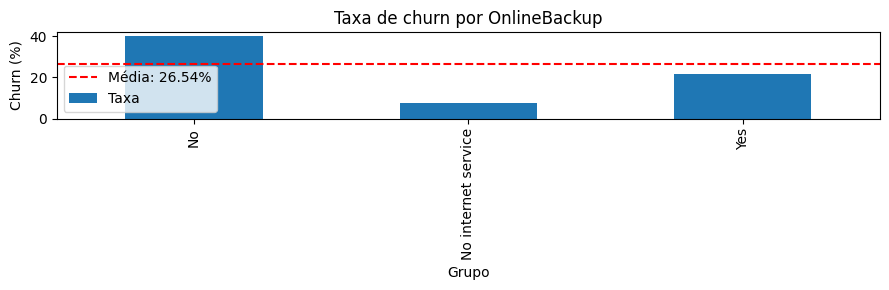

Entre grupos com ao menos 30 clientes, maior taxa: No (39.93%); menor: No internet service (7.40%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,3095,1211,0.3913,DeviceProtection,12.5906
1,No internet service,1526,113,0.0740,DeviceProtection,-19.1320
2,Yes,2422,545,0.2250,DeviceProtection,-4.0349


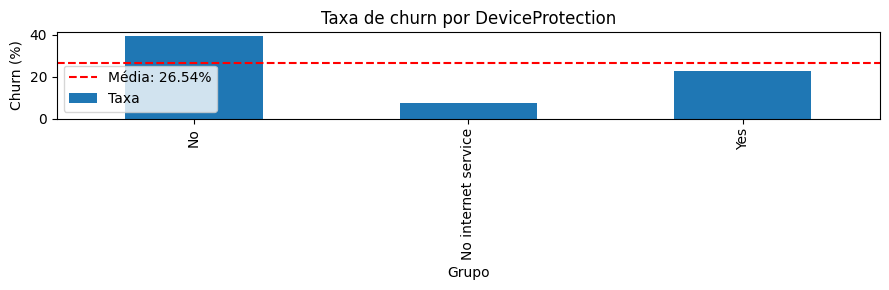

Entre grupos com ao menos 30 clientes, maior taxa: No (39.13%); menor: No internet service (7.40%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,3473,1446,0.4164,TechSupport,15.0985
1,No internet service,1526,113,0.0740,TechSupport,-19.1320
2,Yes,2044,310,0.1517,TechSupport,-11.3706


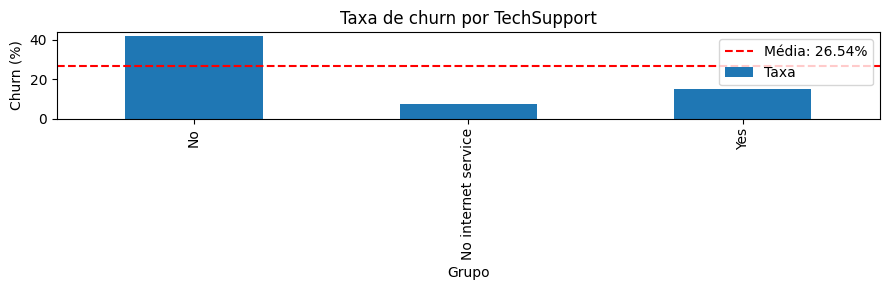

Entre grupos com ao menos 30 clientes, maior taxa: No (41.64%); menor: No internet service (7.40%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,2810,942,0.3352,StreamingTV,6.9861
1,No internet service,1526,113,0.0740,StreamingTV,-19.1320
2,Yes,2707,814,0.3007,StreamingTV,3.5332


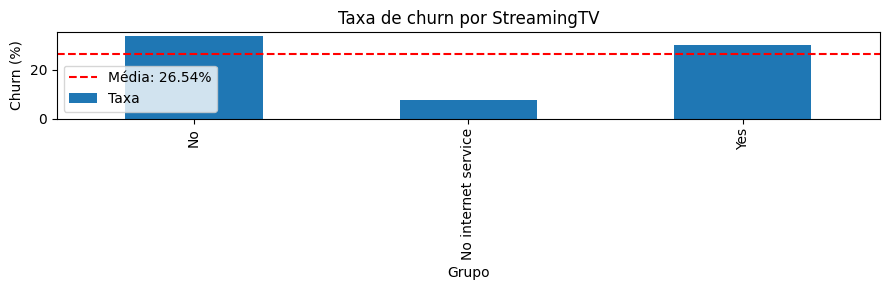

Entre grupos com ao menos 30 clientes, maior taxa: No (33.52%); menor: No internet service (7.40%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,2785,938,0.3368,StreamingMovies,7.1434
1,No internet service,1526,113,0.0740,StreamingMovies,-19.1320
2,Yes,2732,818,0.2994,StreamingMovies,3.4044


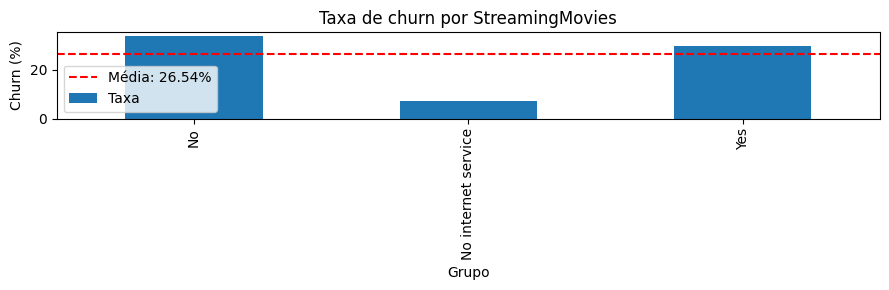

Entre grupos com ao menos 30 clientes, maior taxa: No (33.68%); menor: No internet service (7.40%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,Month-to-month,3875,1655,0.4271,Contract,16.1727
1,One year,1473,166,0.1127,Contract,-15.2675
2,Two year,1695,48,0.0283,Contract,-23.7051


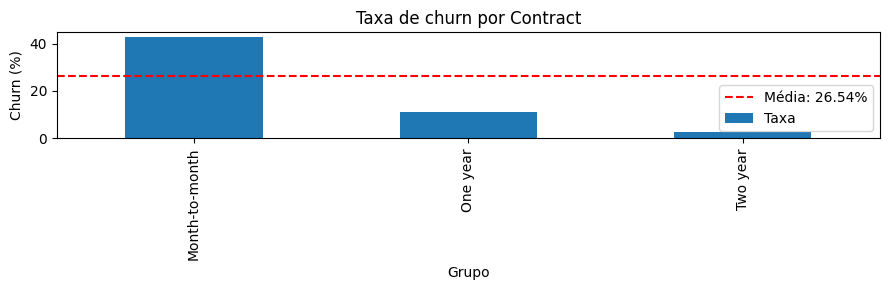

Entre grupos com ao menos 30 clientes, maior taxa: Month-to-month (42.71%); menor: Two year (2.83%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,2872,469,0.1633,PaperlessBilling,-10.2069
1,Yes,4171,1400,0.3357,PaperlessBilling,7.0281


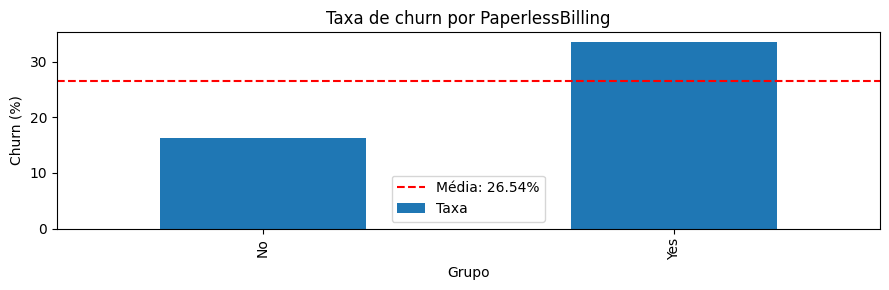

Entre grupos com ao menos 30 clientes, maior taxa: Yes (33.57%); menor: No (16.33%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,Bank transfer (automatic),1544,258,0.1671,PaymentMethod,-9.8271
1,Credit card (automatic),1522,232,0.1524,PaymentMethod,-11.2939
2,Electronic check,2365,1071,0.4529,PaymentMethod,18.7484
3,Mailed check,1612,308,0.1911,PaymentMethod,-7.4303


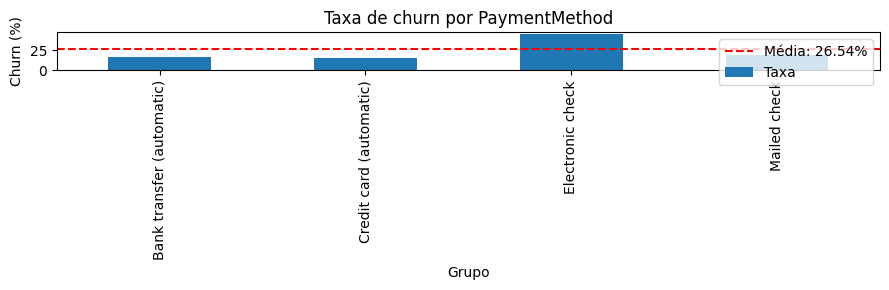

Entre grupos com ao menos 30 clientes, maior taxa: Electronic check (45.29%); menor: Credit card (automatic) (15.24%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,"(18.148999999999997, 35.0]",1735,189,0.1089,MonthlyCharges,-15.6436
1,"(35.0, 51.75]",716,214,0.2989,MonthlyCharges,3.3513
2,"(51.75, 68.5]",825,127,0.1539,MonthlyCharges,-11.1430
3,"(68.5, 85.25]",1614,615,0.3810,MonthlyCharges,11.5671
4,"(85.25, 102.0]",1428,543,0.3803,MonthlyCharges,11.4882
5,"(102.0, 118.75]",725,181,0.2497,MonthlyCharges,-1.5715


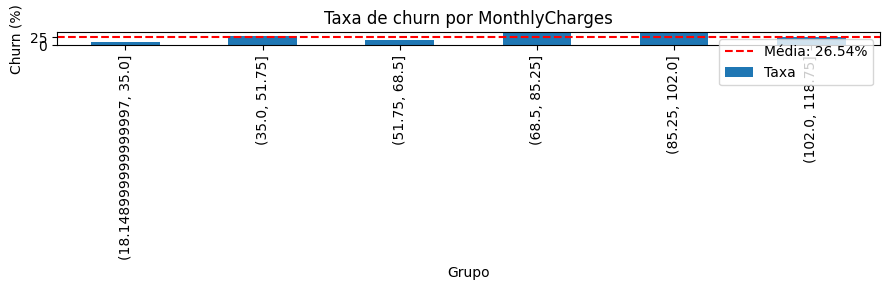

Entre grupos com ao menos 30 clientes, maior taxa: (68.5, 85.25] (38.10%); menor: (18.148999999999997, 35.0] (10.89%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,"(-8.686, 1447.467]",3614,1224,0.3387,TotalCharges,7.3313
1,"(1447.467, 2894.933]",1168,282,0.2414,TotalCharges,-2.3932
2,"(2894.933, 4342.4]",794,150,0.1889,TotalCharges,-7.6453
3,"(4342.4, 5789.867]",680,116,0.1706,TotalCharges,-9.4782
4,"(5789.867, 7237.333]",524,71,0.1355,TotalCharges,-12.9874
5,"(7237.333, 8684.8]",263,26,0.0989,TotalCharges,-16.6511


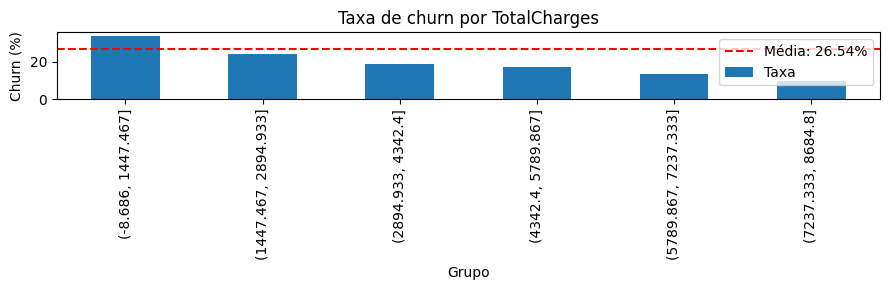

Entre grupos com ao menos 30 clientes, maior taxa: (-8.686, 1447.467] (33.87%); menor: (7237.333, 8684.8] (9.89%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,0,80,35,0.4375,NumServices,17.2130
1,1,1701,359,0.2111,NumServices,-5.4318
2,2,1188,390,0.3283,NumServices,6.2913
3,3,965,352,0.3648,NumServices,9.9397
4,4,922,289,0.3134,NumServices,4.8079
5,5,908,232,0.2555,NumServices,-0.9863
6,6,676,152,0.2249,NumServices,-4.0518
7,7,395,49,0.1241,NumServices,-14.1319
8,8,208,11,0.0529,NumServices,-21.2485


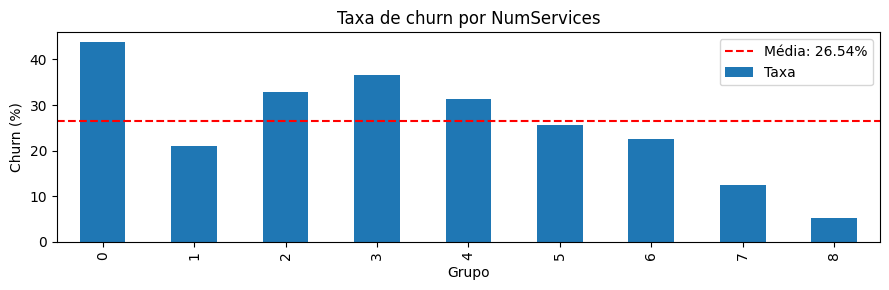

Entre grupos com ao menos 30 clientes, maior taxa: 0 (43.75%); menor: 8 (5.29%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,0-12 meses,2186,1037,0.4744,TenureGroup,20.9013
1,13-24 meses,1024,294,0.2871,TenureGroup,2.1740
2,25-48 meses,1594,325,0.2039,TenureGroup,-6.1480
3,49-72 meses,2239,213,0.0951,TenureGroup,-17.0238


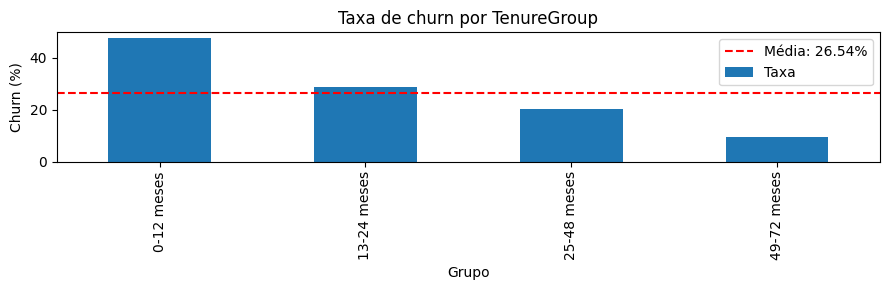

Entre grupos com ao menos 30 clientes, maior taxa: 0-12 meses (47.44%); menor: 49-72 meses (9.51%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,No,3977,1379,0.3467,AutomaticPayment,8.1374
1,Yes,3066,490,0.1598,AutomaticPayment,-10.5553


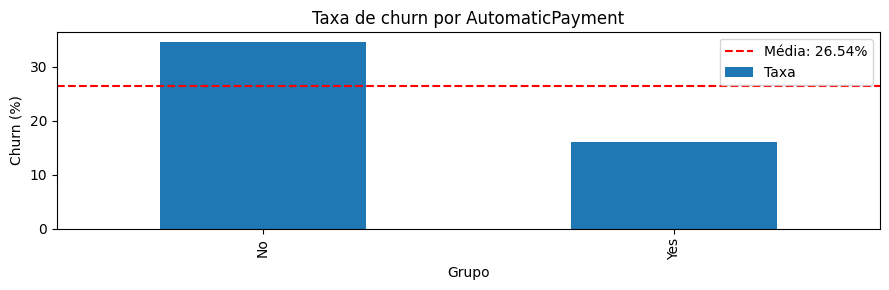

Entre grupos com ao menos 30 clientes, maior taxa: No (34.67%); menor: Yes (15.98%). Associação descritiva, sem inferência causal.


,Grupo,Clientes,Churns,Taxa,Variável,Diferença (p.p.)
0,"(13.666, 31.712]",1685,177,0.1050,AvgMonthlySpend,-16.0325
1,"(31.712, 49.65]",594,181,0.3047,AvgMonthlySpend,3.9344
2,"(49.65, 67.588]",1007,189,0.1877,AvgMonthlySpend,-7.7684
3,"(67.588, 85.525]",1639,602,0.3673,AvgMonthlySpend,10.1927
4,"(85.525, 103.462]",1445,547,0.3785,AvgMonthlySpend,11.3177
5,"(103.462, 121.4]",673,173,0.2571,AvgMonthlySpend,-0.8312


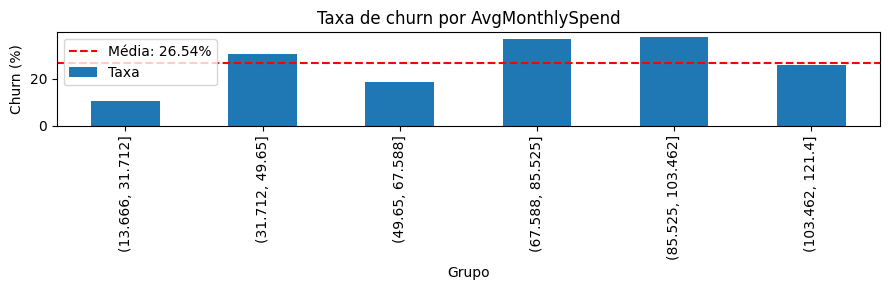

Entre grupos com ao menos 30 clientes, maior taxa: (85.525, 103.462] (37.85%); menor: (13.666, 31.712] (10.50%). Associação descritiva, sem inferência causal.


In [12]:
# Análise descritiva da base completa, conforme atividade do professor.
# As faixas abaixo não são usadas como novos atributos dos modelos.
display(df.nunique().to_frame('Valores distintos após limpeza'))
global_rate=df['Churn'].mean()
group_tables=[]
for col in df.columns.drop('Churn'):
    x=df[col]
    if pd.api.types.is_numeric_dtype(x) and x.nunique()>10:
        group=pd.cut(x, bins=6, include_lowest=True)
    else:
        group=x
    t=pd.DataFrame({'Grupo':group,'Churn':df['Churn']}).groupby('Grupo',observed=True,dropna=False)['Churn'].agg(Clientes='size',Churns='sum',Taxa='mean').reset_index()
    t['Variável']=col
    t['Diferença (p.p.)']=100*(t['Taxa']-global_rate)
    group_tables.append(t)
    display(t)
    ax=t.set_index('Grupo')['Taxa'].mul(100).plot.bar(figsize=(9,3),title=f'Taxa de churn por {col}')
    ax.axhline(global_rate*100,color='red',linestyle='--',label=f'Média: {global_rate:.2%}')
    ax.set_ylabel('Churn (%)'); ax.legend(); plt.tight_layout(); plt.show()
    stable=t[t['Clientes']>=30]
    if len(stable):
        high=stable.loc[stable['Taxa'].idxmax()]; low=stable.loc[stable['Taxa'].idxmin()]
        print(f"Entre grupos com ao menos 30 clientes, maior taxa: {high['Grupo']} ({high['Taxa']:.2%}); menor: {low['Grupo']} ({low['Taxa']:.2%}). Associação descritiva, sem inferência causal.")
churn_groups=pd.concat(group_tables,ignore_index=True)

<a id="sintese-exploratoria"></a>

### Síntese da análise exploratória

| Característica | Taxa de churn | Leitura |
|---|---:|---|
| Até 12 meses de permanência | 47,44% | Acima da média global de 26,54% |
| Mais de 60 até 72 meses | 6,61% | Menor taxa entre as faixas de permanência |
| Contrato mensal | 42,71% | Acima da média |
| Contrato de dois anos | 2,83% | Abaixo da média |
| Cheque eletrônico | 45,29% | Maior taxa entre os meios de pagamento |
| Cartão com pagamento automático | 15,24% | Abaixo da média |
| Fibra óptica | 41,89% | Acima da taxa de DSL, de 18,96% |

O tempo de permanência apresenta redução progressiva da taxa entre as faixas. Já as cobranças mensais não apresentam relação monotônica: a taxa é de **38,10%** na faixa acima de 68,50 até 85,25 e de **24,97%** acima de 102 até 118,75. Assim, não se conclui simplesmente que mensalidades maiores implicam mais churn.

As taxas por gênero são próximas (**26,92% e 26,16%**), com menor diferenciação nessa análise isolada. Os resultados descrevem grupos e não efeitos causais independentes. A frequência mínima de 30 registros usada no comentário automático é apenas uma regra de apresentação, não um teste de significância.

Os limites negativos e as casas decimais extensas de alguns intervalos decorrem da representação automática do `pd.cut`; não indicam registros negativos. A apresentação complementar a seguir utiliza os mínimos e máximos efetivamente observados em cada grupo.

**tenure — limites observados em cada grupo**

,Faixa observada,Clientes,Churns,Churn (%)
0,0.00 a 12.00,2186,1037,47.4400
1,13.00 a 24.00,1024,294,28.7100
2,25.00 a 36.00,832,180,21.6300
3,37.00 a 48.00,762,145,19.0300
4,49.00 a 60.00,832,120,14.4200
5,61.00 a 72.00,1407,93,6.6100


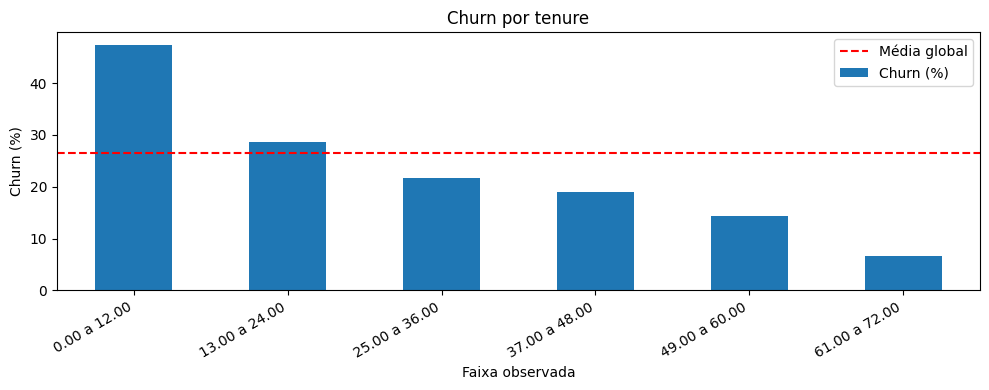

**MonthlyCharges — limites observados em cada grupo**

,Faixa observada,Clientes,Churns,Churn (%)
0,18.25 a 35.00,1735,189,10.8900
1,35.05 a 51.75,716,214,29.8900
2,51.80 a 68.50,825,127,15.3900
3,68.55 a 85.25,1614,615,38.1000
4,85.30 a 102.00,1428,543,38.0300
5,102.05 a 118.75,725,181,24.9700


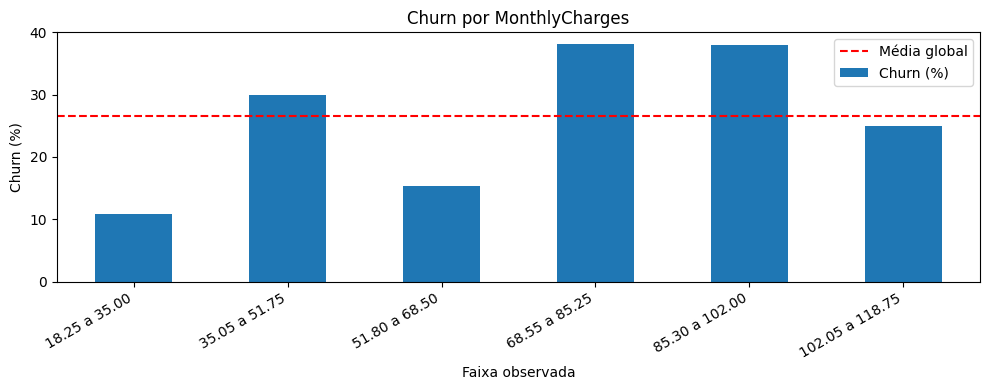

**TotalCharges — limites observados em cada grupo**

,Faixa observada,Clientes,Churns,Churn (%)
0,0.00 a 1446.80,3614,1224,33.8700
1,1447.90 a 2894.55,1168,282,24.1400
2,2896.40 a 4338.60,794,150,18.8900
3,4345.00 a 5785.65,680,116,17.0600
4,5791.10 a 7234.80,524,71,13.5500
5,7238.60 a 8684.80,263,26,9.8900


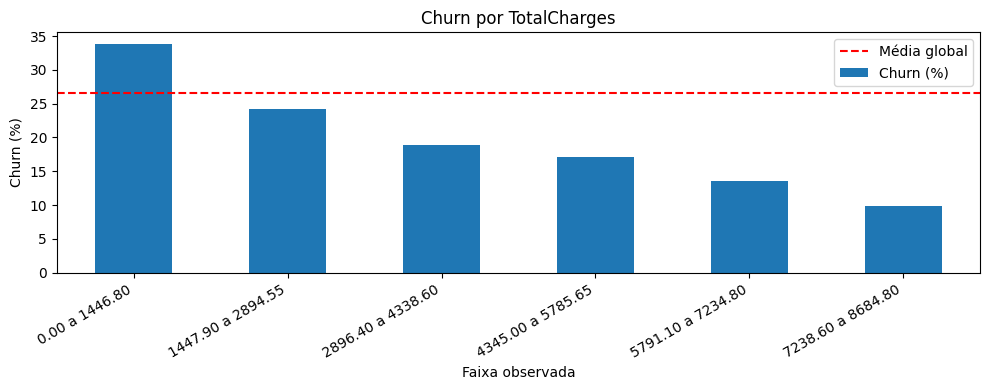

**AvgMonthlySpend — limites observados em cada grupo**

,Faixa observada,Clientes,Churns,Churn (%)
0,13.78 a 31.68,1685,177,10.5000
1,31.77 a 49.65,594,181,30.4700
2,49.72 a 67.57,1007,189,18.7700
3,67.60 a 85.52,1639,602,36.7300
4,85.53 a 103.46,1445,547,37.8500
5,103.46 a 121.40,673,173,25.7100


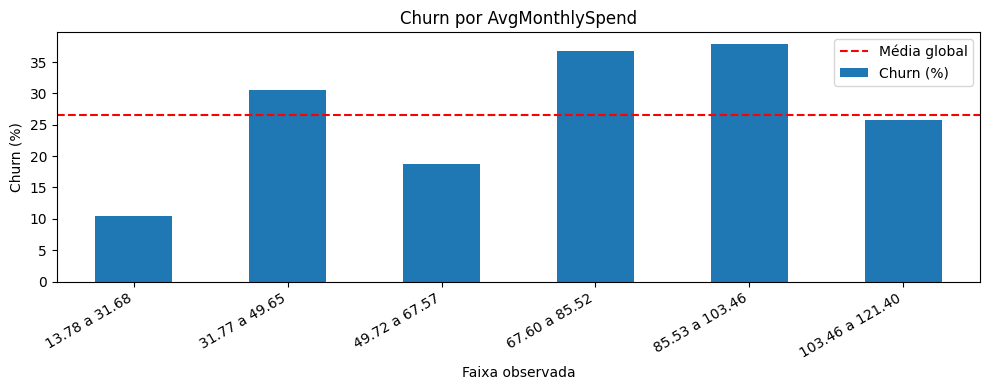

In [13]:
# Apenas apresentação: conserva os grupos e as taxas da análise anterior.
for col in ['tenure','MonthlyCharges','TotalCharges','AvgMonthlySpend']:
    bins = pd.cut(df[col], bins=6, include_lowest=True)
    table = df.groupby(bins, observed=True).agg(
        Minimo=(col,'min'), Maximo=(col,'max'), Clientes=('Churn','size'),
        Churns=('Churn','sum'), Taxa=('Churn','mean')).reset_index(drop=True)
    table.insert(0,'Faixa observada',table.apply(lambda r:f"{r.Minimo:.2f} a {r.Maximo:.2f}",axis=1))
    table['Churn (%)']=100*table['Taxa']
    display(Markdown(f'**{col} — limites observados em cada grupo**'))
    display(table[['Faixa observada','Clientes','Churns','Churn (%)']].round(2))
    ax=table.set_index('Faixa observada')['Churn (%)'].plot.bar(figsize=(10,4),title=f'Churn por {col}')
    ax.axhline(df.Churn.mean()*100,color='red',linestyle='--',label='Média global')
    ax.set_ylabel('Churn (%)'); ax.legend(); plt.xticks(rotation=30,ha='right'); plt.tight_layout(); plt.show()


<a id="secao-12"></a>

## 9. Separação entre variáveis explicativas e alvo

A base será dividida em:
- `X`: variáveis utilizadas para prever;
- `y`: variável-alvo (`Churn`).

Depois será feita uma divisão de **80% para treino e 20% para teste**, utilizando `stratify=y` para preservar aproximadamente a mesma proporção de churn nos dois conjuntos.


In [14]:

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)
print("\nProporção de Churn no treino:", round(y_train.mean(), 4))
print("Proporção de Churn no teste:", round(y_test.mean(), 4))


Treino: (5634, 23)
Teste: (1409, 23)

Proporção de Churn no treino: 0.2654
Proporção de Churn no teste: 0.2654


### Divisão entre treino e teste

A divisão utilizada foi:

- **80% treino:** 5.634 registros;
- **20% teste:** 1.409 registros.

Foi utilizado:

- `random_state=42` para tornar a divisão reproduzível;
- `stratify=y` para manter a proporção de churn nos dois conjuntos.

A proporção de churn ficou em aproximadamente **26,54% tanto no treino quanto no teste**.


<a id="secao-13"></a>

## 10. Conversão das variáveis textuais e escalonamento

### Variáveis categóricas
Será utilizado **One-Hot Encoding**, que cria colunas binárias para as categorias sem impor uma ordem artificial.

### Variáveis numéricas
Será utilizado:
1. `SimpleImputer(strategy='median')` para eventuais valores numéricos faltantes;
2. **`StandardScaler`** para padronização.

O `StandardScaler` transforma as variáveis para uma escala comparável, o que é particularmente importante para modelos lineares como Regressão Logística e SGD.

Todo o pré-processamento é realizado dentro de um `Pipeline`, evitando vazamento de informação do conjunto de teste para o treino.


In [15]:

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Variáveis numéricas:")
print(numeric_features)

print("\nVariáveis categóricas:")
print(categorical_features)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


Variáveis numéricas:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'NumServices', 'AvgMonthlySpend']

Variáveis categóricas:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup', 'AutomaticPayment']


In [16]:
# Demonstração visual do One-Hot Encoding
# O pré-processador é ajustado somente com X_train.

X_train_prepared = preprocessor.fit_transform(X_train)
feature_names_preview = preprocessor.get_feature_names_out()

preview_matrix = X_train_prepared[:5]

if hasattr(preview_matrix, "toarray"):
    preview_matrix = preview_matrix.toarray()

preview_df = pd.DataFrame(
    preview_matrix,
    columns=feature_names_preview
)

# Mostra algumas das colunas categóricas transformadas em 0 e 1
dummy_columns = [
    col for col in preview_df.columns
    if col.startswith("cat__")
][:15]

print("Exemplo de colunas criadas pelo One-Hot Encoding (0/1):")
display(preview_df[dummy_columns])

Exemplo de colunas criadas pelo One-Hot Encoding (0/1):


,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,cat__PhoneService_No,cat__PhoneService_Yes,cat__MultipleLines_No,cat__MultipleLines_No phone service,cat__MultipleLines_Yes,cat__InternetService_DSL,cat__InternetService_Fiber optic,cat__InternetService_No,cat__OnlineSecurity_No
0,0.0000,1.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000
1,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
2,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000
3,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
4,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000


### Resposta ao critério — conversão das variáveis textuais

Foram utilizadas duas estratégias:

1. **Variável-alvo (`Churn`)**
   - `No → 0`
   - `Yes → 1`

2. **Variáveis categóricas explicativas**
   - utilização de **One-Hot Encoding**;
   - cada categoria passa a possuir sua própria coluna;
   - a presença da categoria é representada por **1** e a ausência por **0**.

Exemplo conceitual:

| `Contract` original | `Month-to-month` | `One year` | `Two year` |
|---|---:|---:|---:|
| Month-to-month | 1 | 0 | 0 |
| One year | 0 | 1 | 0 |
| Two year | 0 | 0 | 1 |

Isso evita atribuir uma ordem numérica artificial às categorias.

### Resposta ao critério — escalonamento

Foi utilizado **`StandardScaler`** somente nas variáveis numéricas.

O StandardScaler centraliza e padroniza as variáveis, deixando-as em escalas comparáveis. Isso é especialmente relevante para **Regressão Logística** e **SGD**, pois esses algoritmos são sensíveis à escala dos atributos.

As variáveis categóricas não passam pelo StandardScaler; elas são tratadas pelo **One-Hot Encoding**.

In [17]:
# Experimento de engenharia: mesma configuração e mesmas divisões, somente treino.
derived=['NumServices','TenureGroup','AutomaticPayment','AvgMonthlySpend']
ablation_rows=[]
for label, cols in [('Originais',[c for c in X_train.columns if c not in derived]),('Originais + derivados',list(X_train.columns))]:
    nums=[c for c in numeric_features if c in cols]
    cats=[c for c in categorical_features if c in cols]
    prep=ColumnTransformer([('num',clone(numeric_transformer),nums),('cat',clone(categorical_transformer),cats)])
    pipe=Pipeline([('preprocessor',prep),('model',LogisticRegression(class_weight='balanced',max_iter=5000,random_state=42))])
    scores=cross_validate(pipe,X_train[cols],y_train,cv=StratifiedKFold(5,shuffle=True,random_state=42),scoring='balanced_accuracy')
    ablation_rows.append({'Atributos':label,'BA média':scores['test_score'].mean(),'Desvio':scores['test_score'].std()})
display(pd.DataFrame(ablation_rows))
print('Experimento diagnóstico com regressão logística; não demonstra ganho universal dos atributos. Os oito cenários seguintes mantêm o mesmo conjunto de atributos para comparabilidade.')

,Atributos,BA média,Desvio
0,Originais,0.7654,0.0206
1,Originais + derivados,0.7650,0.0184


Experimento diagnóstico com regressão logística; não demonstra ganho universal dos atributos. Os oito cenários seguintes mantêm o mesmo conjunto de atributos para comparabilidade.


### Resultado do experimento de engenharia de atributos

A Balanced Accuracy média passou de **76,54% para 76,50%**, diferença aproximada de **−0,04 ponto percentual**. Não se observou ganho com os atributos derivados nessa configuração. Os desvios entre divisões foram de 2,06 e 1,84 pontos percentuais; a diferença das médias não constitui evidência de superioridade de um conjunto. O experimento utiliza Regressão Logística ponderada e não generaliza a conclusão a todos os algoritmos.

<a id="secao-14"></a>

## Atividade 2 - Tratamento do desbalanceamento com class_weight

**Melhoria solicitada:** incluir o parâmetro `class_weight` no treinamento dos quatro algoritmos.

Regressão Logística, SGD Classifier, Árvore de Decisão e Floresta Aleatória são avaliados com `class_weight="balanced"` e comparados com controles que utilizam `class_weight=None`. A ponderação modifica o peso das classes durante o ajuste, sem alterar a proporção de clientes na base.

**Localização da implementação:** a célula de treinamento da Atividade 3 aplica a ponderação aos quatro algoritmos por meio de `set_params(class_weight=weight)`. As duas atividades compartilham o mesmo experimento, permitindo comparar oito cenários. A tabela de parâmetros imediatamente após o treinamento comprova a configuração de cada cenário.

<a id="secao-15"></a>

## Atividade 3 - GridSearchCV e avaliação de sobreajuste

**Melhoria solicitada:** testar pelo menos dois hiperparâmetros de cada algoritmo com grid search e avaliar o risco de overfitting.

| Algoritmo | Hiperparâmetro 1 | Hiperparâmetro 2 |
|---|---|---|
| Regressão Logística | C | fit_intercept |
| SGD Classifier | alpha | penalty |
| Árvore de Decisão | max_depth | min_samples_leaf |
| Floresta Aleatória | max_depth | min_samples_leaf |

Cada cenário utiliza a mesma grade de parâmetros, o mesmo conjunto de atributos e cinco divisões estratificadas de validação. O pipeline completo é ajustado dentro de cada divisão. A busca realiza 300 ajustes de validação, além dos reajustes finais.

A seleção utiliza a maior Balanced Accuracy média na validação; a comparação entre os oito cenários desempata por F1 macro e nome. A diferença entre treino e validação e o desvio entre divisões permitem investigar sobreajuste, sem garantir sua eliminação. As tabelas a seguir registram os resultados, e a interpretação da seleção na Atividade 4 discute essas diferenças.

In [18]:
# Comparações realizadas exclusivamente no conjunto de treino.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'balanced_accuracy': 'balanced_accuracy', 'accuracy': 'accuracy',
           'f1_macro': 'f1_macro', 'recall_churn': 'recall', 'f1_churn': 'f1'}
specs = {
 'Regressão Logística': (LogisticRegression(max_iter=5000, random_state=42),
     {'model__C':[0.1,1,10], 'model__fit_intercept':[True,False]}),
 'SGD Classifier': (SGDClassifier(loss='log_loss', max_iter=5000, random_state=42),
     {'model__alpha':[0.0001,0.001,0.01], 'model__penalty':['l2','l1']}),
 'Árvore de Decisão': (DecisionTreeClassifier(random_state=42),
     {'model__max_depth':[3,8,None], 'model__min_samples_leaf':[5,10,20]}),
 'Floresta Aleatória': (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1),
     {'model__max_depth':[5,10,None], 'model__min_samples_leaf':[2,5,10]})
}
searches, trained_pipelines, cv_rows = {}, {}, []
for name, (model, grid) in specs.items():
    for weight in [None, 'balanced']:
        label = name + (' | sem ponderação' if weight is None else ' | ponderado')
        pipe = Pipeline([('preprocessor', clone(preprocessor)),
                         ('model', clone(model).set_params(class_weight=weight))])
        search = GridSearchCV(pipe, grid, scoring=scoring, refit='balanced_accuracy',
                              cv=cv, n_jobs=2, return_train_score=True, error_score='raise')
        search.fit(X_train, y_train)
        searches[label] = search
        trained_pipelines[label] = search.best_estimator_
        k=search.best_index_; r=search.cv_results_
        cv_rows.append({'Modelo':label, 'BA validação':r['mean_test_balanced_accuracy'][k],
                        'Desvio BA':r['std_test_balanced_accuracy'][k],
                        'BA treino':r['mean_train_balanced_accuracy'][k],
                        'F1 macro validação':r['mean_test_f1_macro'][k],
                        'Parâmetros':search.best_params_})
        print('Concluído:', label)
cv_results = pd.DataFrame(cv_rows)
cv_results['Diferença treino-validação'] = cv_results['BA treino']-cv_results['BA validação']
cv_results = cv_results.sort_values(['BA validação','F1 macro validação','Modelo'],
                                   ascending=[False,False,True]).reset_index(drop=True)
display(cv_results)
# Seleção definida antes da avaliação no teste.
selected_model_name = cv_results.iloc[0]['Modelo']
selected_pipeline = trained_pipelines[selected_model_name]
results=[]
for label, pipe in trained_pipelines.items():
    pred=pipe.predict(X_test)
    results.append({'Modelo':label, 'Accuracy':accuracy_score(y_test,pred),
       'Balanced Accuracy':balanced_accuracy_score(y_test,pred),
       'Precision':precision_score(y_test,pred,zero_division=0),
       'Recall':recall_score(y_test,pred,zero_division=0),
       'F1-score':f1_score(y_test,pred,zero_division=0),
       'F1 macro':f1_score(y_test,pred,average='macro',zero_division=0)})
results_df=pd.DataFrame(results)
display(results_df)

Concluído: Regressão Logística | sem ponderação
Concluído: Regressão Logística | ponderado
Concluído: SGD Classifier | sem ponderação
Concluído: SGD Classifier | ponderado
Concluído: Árvore de Decisão | sem ponderação
Concluído: Árvore de Decisão | ponderado
Concluído: Floresta Aleatória | sem ponderação
Concluído: Floresta Aleatória | ponderado


,Modelo,BA validação,Desvio BA,BA treino,F1 macro validação,Parâmetros,Diferença treino-validação
0,Regressão Logística | ponderado,0.7660,0.0183,0.7697,0.7207,"{'model__C': 10, 'model__fit_intercept': True}",0.0038
1,SGD Classifier | ponderado,0.7654,0.0156,0.7658,0.7260,"{'model__alpha': 0.001, 'model__penalty': 'l1'}",0.0004
2,Floresta Aleatória | ponderado,0.7651,0.0151,0.7780,0.7207,"{'model__max_depth': 5, 'model__min_samples_le...",0.0128
3,Árvore de Decisão | ponderado,0.7558,0.0129,0.7587,0.7145,"{'model__max_depth': 3, 'model__min_samples_le...",0.0029
4,Regressão Logística | sem ponderação,0.7197,0.0159,0.7235,0.7330,"{'model__C': 1, 'model__fit_intercept': True}",0.0038
5,SGD Classifier | sem ponderação,0.7173,0.0070,0.7208,0.7301,"{'model__alpha': 0.001, 'model__penalty': 'l2'}",0.0035
6,Floresta Aleatória | sem ponderação,0.7076,0.0159,0.7737,0.7240,"{'model__max_depth': 10, 'model__min_samples_l...",0.0661
7,Árvore de Decisão | sem ponderação,0.6923,0.0130,0.7789,0.6988,"{'model__max_depth': 8, 'model__min_samples_le...",0.0866


,Modelo,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,F1 macro
0,Regressão Logística | sem ponderação,0.7991,0.7096,0.6532,0.5187,0.5782,0.7232
1,Regressão Logística | ponderado,0.7331,0.7509,0.4983,0.7888,0.6108,0.7039
2,SGD Classifier | sem ponderação,0.7949,0.6982,0.6502,0.4920,0.5601,0.7132
3,SGD Classifier | ponderado,0.7480,0.7611,0.5166,0.7888,0.6243,0.7174
4,Árvore de Decisão | sem ponderação,0.7864,0.7060,0.6116,0.5348,0.5706,0.7142
5,Árvore de Decisão | ponderado,0.7459,0.7579,0.5140,0.7834,0.6208,0.7149
6,Floresta Aleatória | sem ponderação,0.7970,0.7047,0.6507,0.5080,0.5706,0.7188
7,Floresta Aleatória | ponderado,0.7452,0.7591,0.5130,0.7888,0.6217,0.7148


In [19]:
# Os objetos searches da execução anterior contêm os parâmetros integrais.
parameter_rows=[]
for name, search in searches.items():
    for parameter, value in search.best_params_.items():
        parameter_rows.append({'Modelo':name,'Parâmetro':parameter,'Valor':str(value)})
    parameter_rows.append({'Modelo':name,'Parâmetro':'model__class_weight',
        'Valor':str(search.best_estimator_.named_steps['model'].class_weight)})
with pd.option_context('display.max_colwidth',None,'display.max_rows',None):
    display(pd.DataFrame(parameter_rows))

,Modelo,Parâmetro,Valor
0,Regressão Logística | sem ponderação,model__C,1
1,Regressão Logística | sem ponderação,model__fit_intercept,True
2,Regressão Logística | sem ponderação,model__class_weight,None
3,Regressão Logística | ponderado,model__C,10
4,Regressão Logística | ponderado,model__fit_intercept,True
5,Regressão Logística | ponderado,model__class_weight,balanced
6,SGD Classifier | sem ponderação,model__alpha,0.001
7,SGD Classifier | sem ponderação,model__penalty,l2
8,SGD Classifier | sem ponderação,model__class_weight,None
9,SGD Classifier | ponderado,model__alpha,0.001


<a id="secao-16"></a>

## Atividade 4 - Comparação de métricas e seleção por métrica balanceada

**Melhoria solicitada:** comparar métricas balanceadas e não balanceadas e selecionar o melhor algoritmo considerando uma métrica balanceada.

A tabela de teste ao final da Atividade 3 apresenta Accuracy, Precision, Recall e F1 de churn, junto a Balanced Accuracy e F1 macro, para os oito cenários. Os gráficos seguintes complementam essa comparação. Balanced Accuracy atribui igual peso ao Recall de cada classe, enquanto F1 macro é a média dos F1 das classes.

O vencedor é definido pela maior Balanced Accuracy média na validação cruzada, antes de avaliar o teste. A interpretação abaixo apresenta os benefícios e os custos da ponderação, seguida da seleção final, das matrizes de confusão e das variáveis utilizadas.

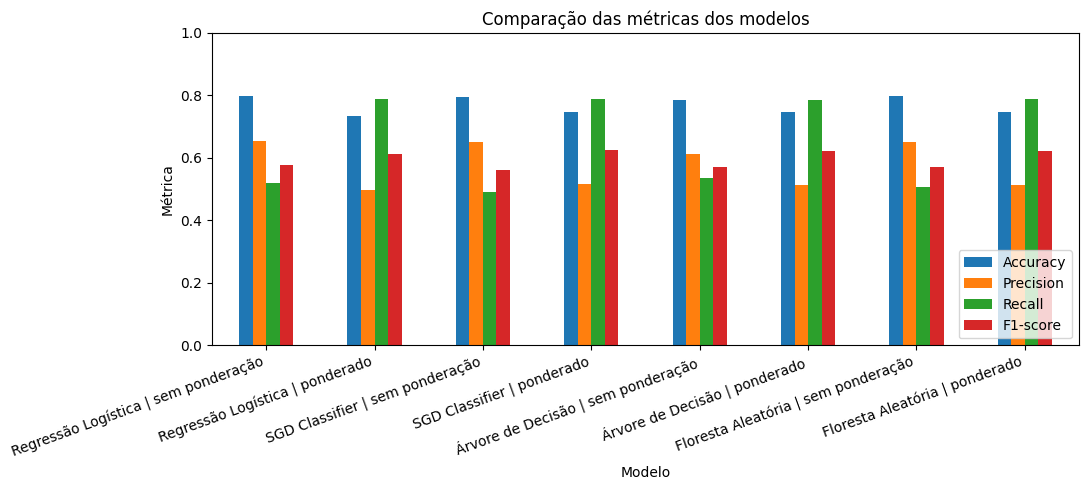

In [20]:

ax = results_df.set_index("Modelo")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1),
    title="Comparação das métricas dos modelos"
)

ax.set_ylabel("Métrica")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


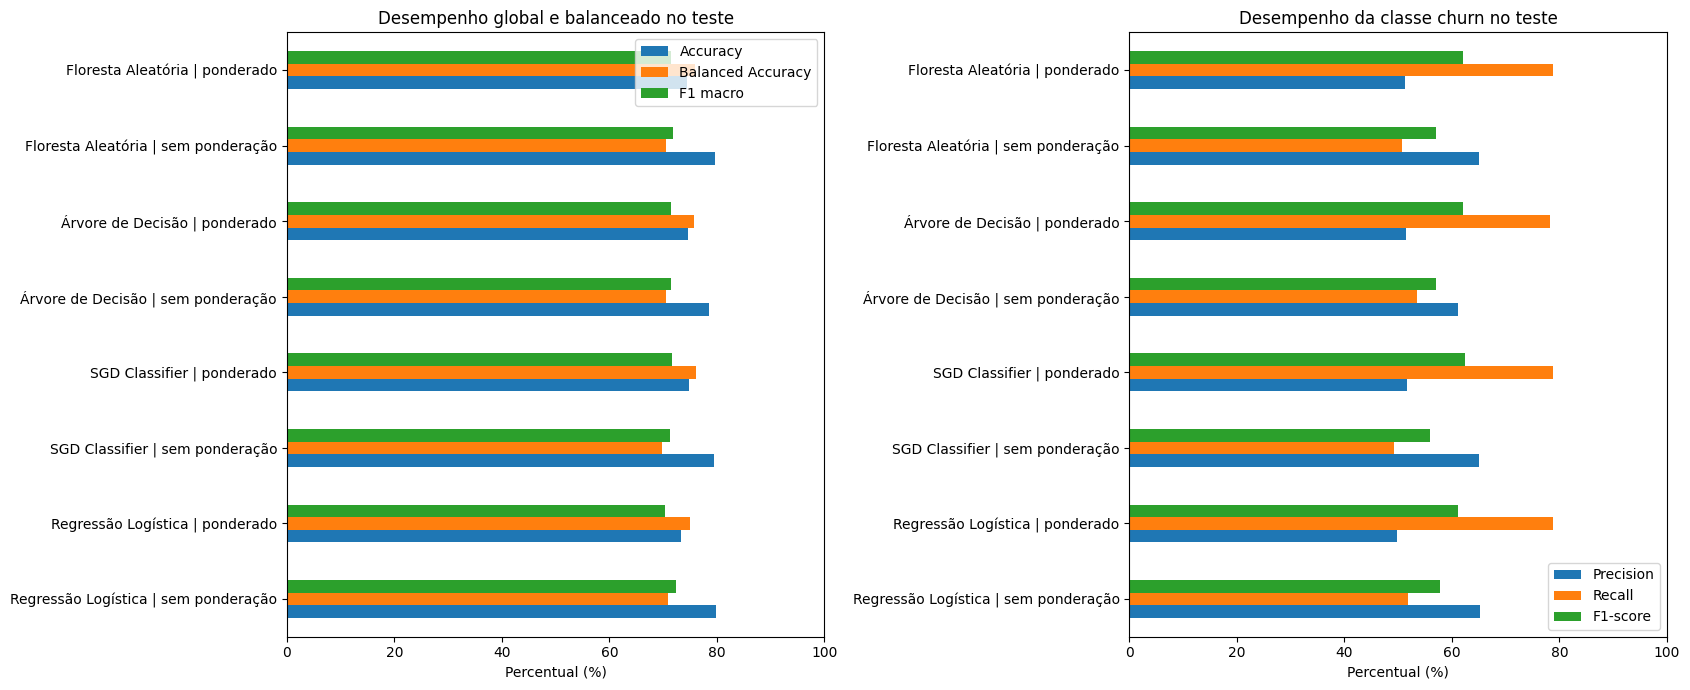

In [21]:
# Complemento ao gráfico original: métricas convencionais e balanceadas.
fig, axes=plt.subplots(1,2,figsize=(17,7))
results_df.set_index('Modelo')[['Accuracy','Balanced Accuracy','F1 macro']].mul(100).plot.barh(ax=axes[0])
results_df.set_index('Modelo')[['Precision','Recall','F1-score']].mul(100).plot.barh(ax=axes[1])
for ax in axes:
    ax.set_xlim(0,100); ax.set_xlabel('Percentual (%)'); ax.set_ylabel('')
axes[0].set_title('Desempenho global e balanceado no teste')
axes[1].set_title('Desempenho da classe churn no teste')
plt.tight_layout(); plt.show()

### Interpretação da comparação

Nos quatro algoritmos, as versões ponderadas e otimizadas apresentaram maior Balanced Accuracy e Recall de churn no teste. Na Regressão Logística, a Balanced Accuracy aumentou de **70,96% para 75,09%**, enquanto o Recall passou de **51,87% para 78,88%**.

Esse ganho foi acompanhado de redução da Precision (**65,32% para 49,83%**), da Accuracy (**79,91% para 73,31%**) e do F1 macro (**72,32% para 70,39%**). O F1 específico de churn aumentou de **57,82% para 61,08%**. Portanto, a ponderação não melhorou todas as métricas: ampliou a identificação dos cancelamentos, com maior quantidade de falsos alertas.

As comparações envolvem versões otimizadas separadamente. Assim, refletem a ponderação e os hiperparâmetros selecionados em conjunto, sem isolar causalmente o efeito de class_weight.

<a id="secao-17"></a>

## 12. Seleção do modelo final

A **Regressão Logística ponderada** foi selecionada pela maior Balanced Accuracy média na validação cruzada (**76,60%**), utilizando `C=10`, `fit_intercept=True` e `class_weight="balanced"`. As médias do SGD ponderado (**76,54%**) e da Floresta Aleatória ponderada (**76,51%**) foram próximas. Essas diferenças não demonstram superioridade estatística da Regressão Logística.

No teste, o SGD ponderado obteve Balanced Accuracy de **76,11%**, superior aos **75,09%** da Regressão Logística. Mantém-se a escolha definida na validação, evitando selecionar novamente após consultar o teste.

A diferença entre treino e validação da Regressão Logística ponderada foi de aproximadamente **0,38 ponto percentual**, sem grande discrepância observada nesse diagnóstico. A árvore e a floresta sem ponderação apresentaram diferenças de **8,66 e 6,61 pontos percentuais**, respectivamente, indicando maior sobreajuste. Esses indicadores não garantem generalização para dados novos.


In [22]:
print('Modelo selecionado na validação:', selected_model_name)
display(cv_results.head(1))
display(results_df.loc[results_df['Modelo'].eq(selected_model_name)])

Modelo selecionado na validação: Regressão Logística | ponderado


,Modelo,BA validação,Desvio BA,BA treino,F1 macro validação,Parâmetros,Diferença treino-validação
0,Regressão Logística | ponderado,0.7660,0.0183,0.7697,0.7207,"{'model__C': 10, 'model__fit_intercept': True}",0.0038


,Modelo,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,F1 macro
1,Regressão Logística | ponderado,0.7331,0.7509,0.4983,0.7888,0.6108,0.7039


<a id="secao-18"></a>

## 13. Matrizes de confusão dos modelos com e sem ponderação

TN e TP são acertos; FP representa um alerta incorreto e FN um cancelamento não identificado. As contagens permitem avaliar o volume operacional dos erros. A normalização por classe permite comparar taxas de identificação sem a predominância numérica dos não cancelamentos.

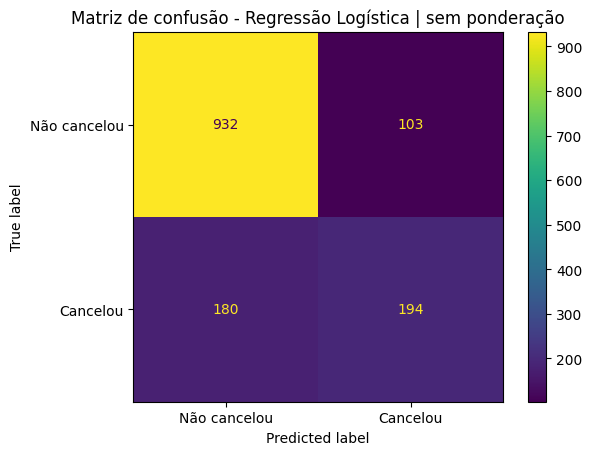

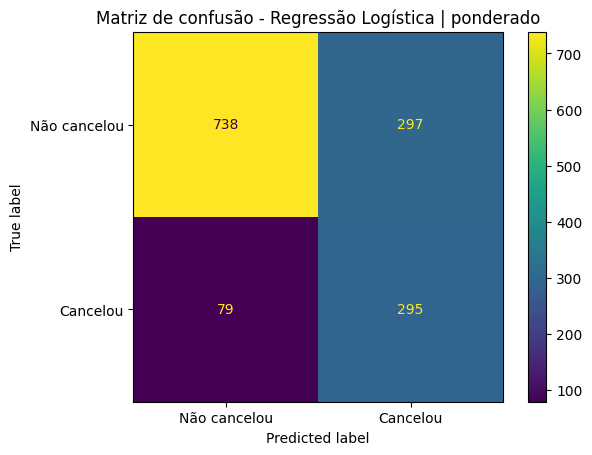

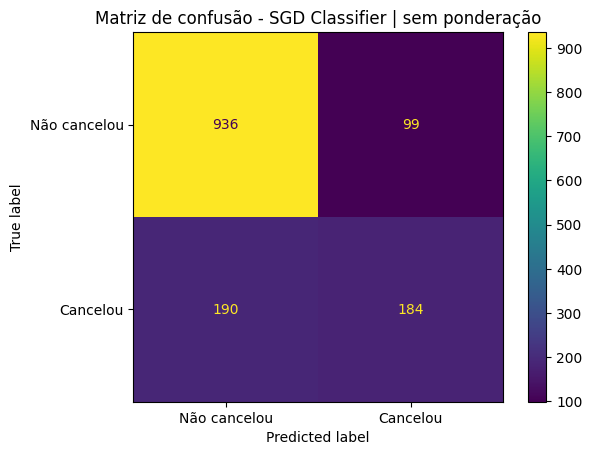

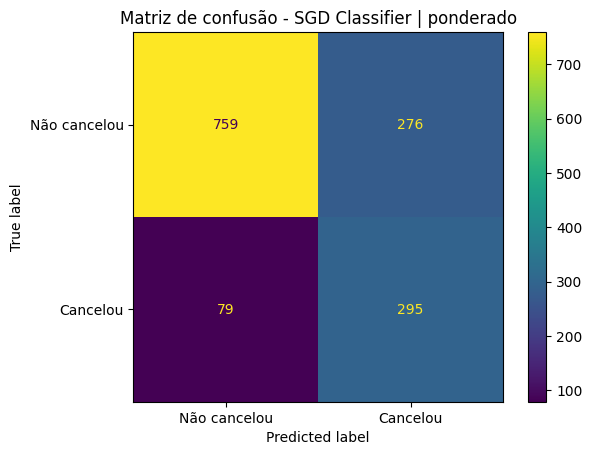

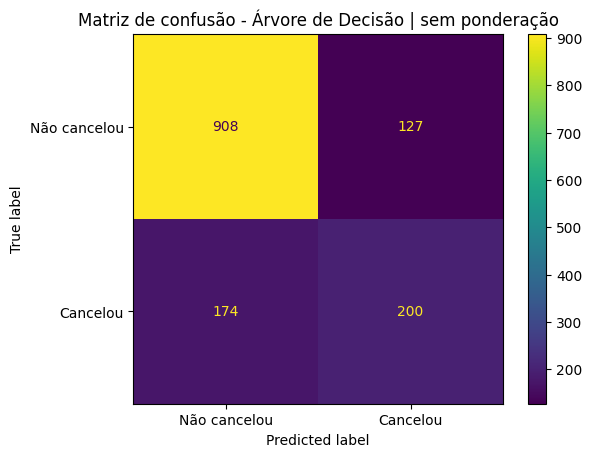

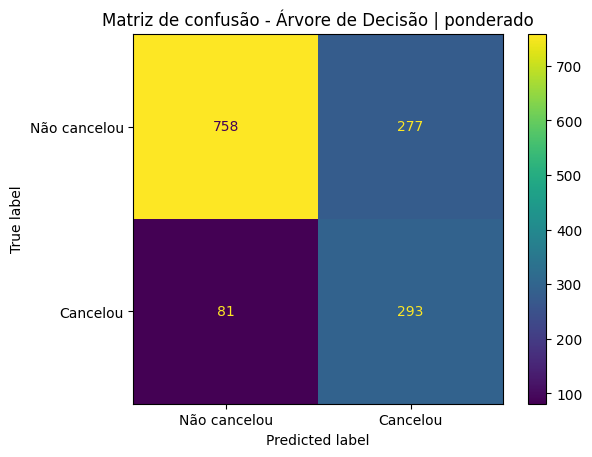

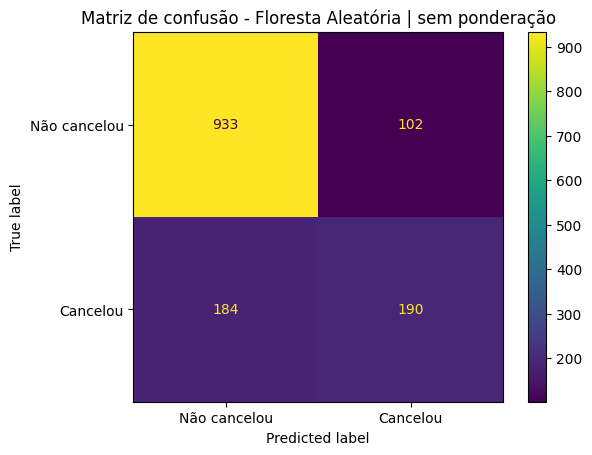

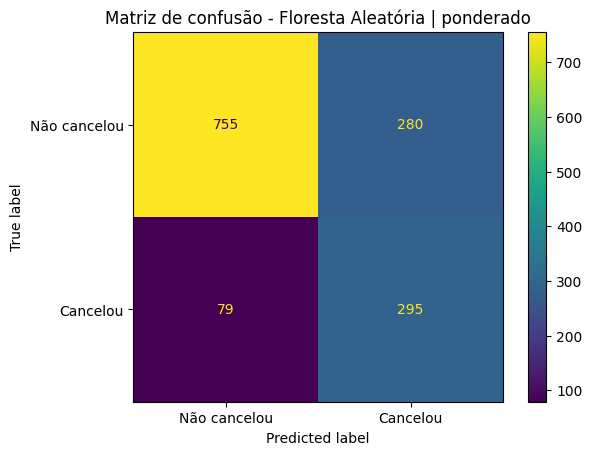

Resumo numérico das matrizes de confusão:


,Modelo,TN,FP,FN,TP
0,Regressão Logística | sem ponderação,932,103,180,194
1,Regressão Logística | ponderado,738,297,79,295
2,SGD Classifier | sem ponderação,936,99,190,184
3,SGD Classifier | ponderado,759,276,79,295
4,Árvore de Decisão | sem ponderação,908,127,174,200
5,Árvore de Decisão | ponderado,758,277,81,293
6,Floresta Aleatória | sem ponderação,933,102,184,190
7,Floresta Aleatória | ponderado,755,280,79,295



Relatório detalhado do modelo selecionado: Regressão Logística | ponderado

              precision    recall  f1-score   support

Não cancelou     0.9033    0.7130    0.7970      1035
    Cancelou     0.4983    0.7888    0.6108       374

    accuracy                         0.7331      1409
   macro avg     0.7008    0.7509    0.7039      1409
weighted avg     0.7958    0.7331    0.7475      1409



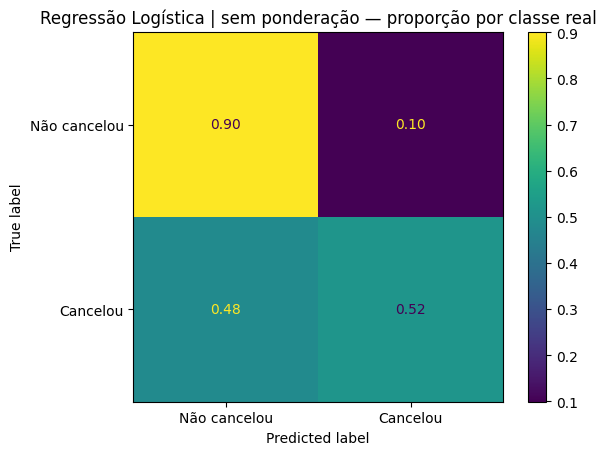

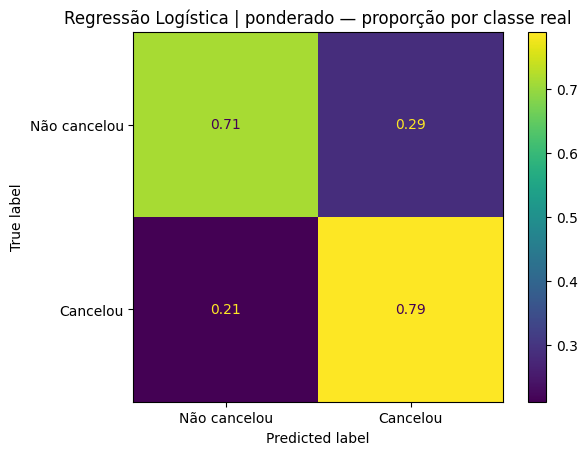

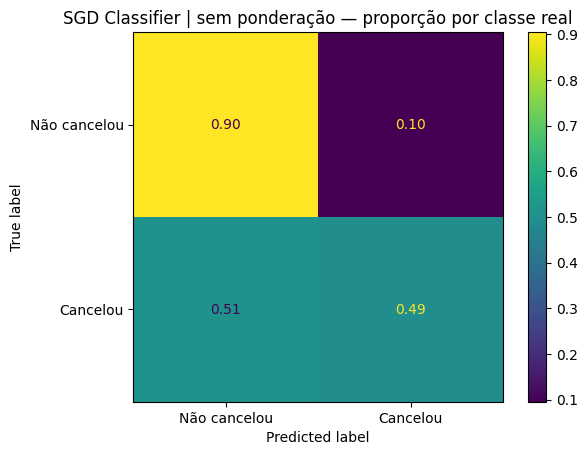

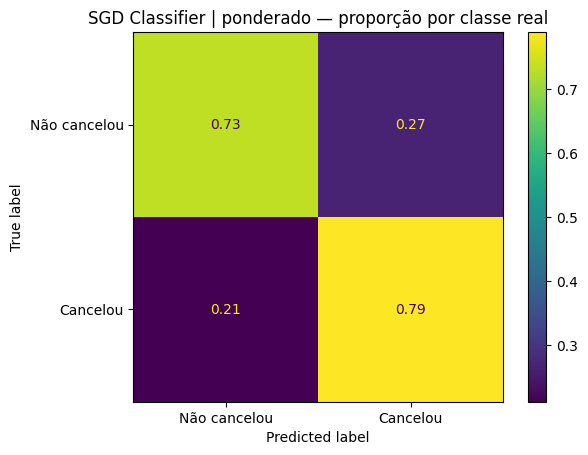

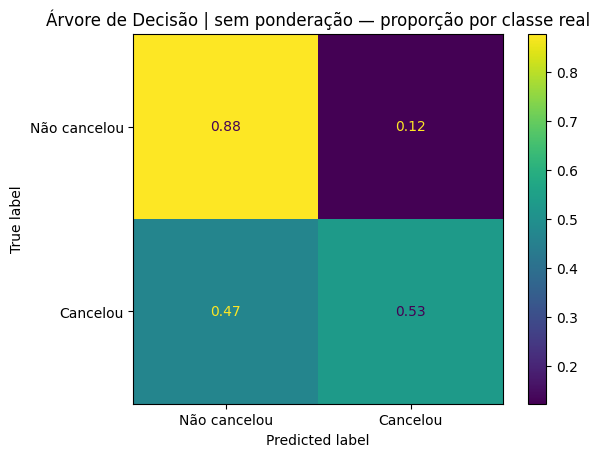

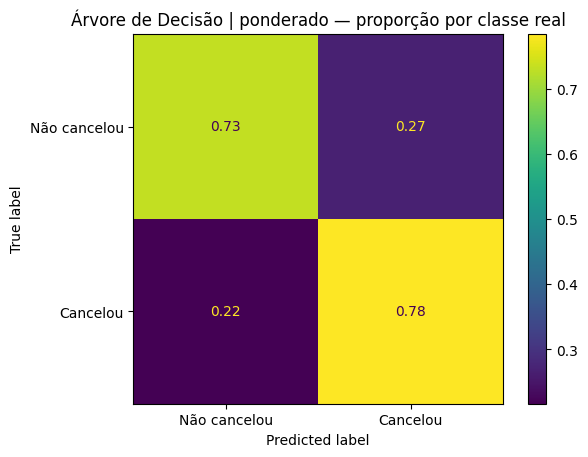

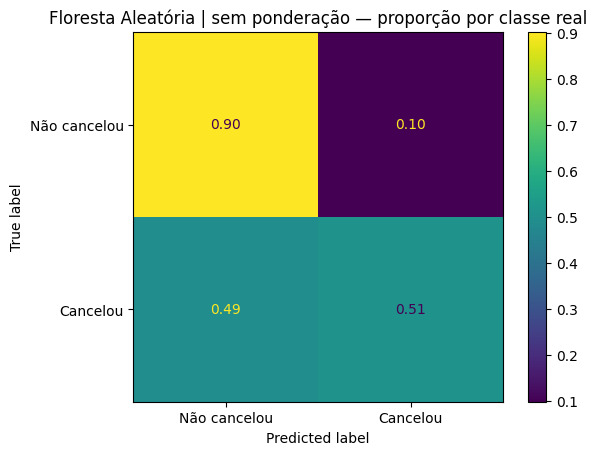

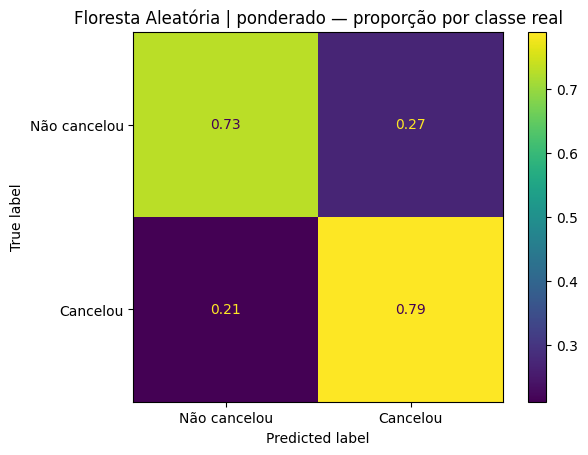

In [23]:
confusion_rows = []

for name, pipe in trained_pipelines.items():
    y_pred_model = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred_model)

    tn, fp, fn, tp = cm.ravel()

    confusion_rows.append({
        "Modelo": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

    # Uma figura separada para cada modelo
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Não cancelou", "Cancelou"]
    )
    disp.plot(values_format="d")
    plt.title(f"Matriz de confusão - {name}")
    plt.show()

confusion_df = pd.DataFrame(confusion_rows)

print("Resumo numérico das matrizes de confusão:")
display(confusion_df)

print(f"\nRelatório detalhado do modelo selecionado: {selected_model_name}\n")

y_pred_selected = selected_pipeline.predict(X_test)

print(classification_report(
    y_test,
    y_pred_selected,
    target_names=["Não cancelou", "Cancelou"],
    digits=4
))
for name, pipe in trained_pipelines.items():
    ConfusionMatrixDisplay.from_predictions(y_test, pipe.predict(X_test), normalize='true',
        display_labels=['Não cancelou','Cancelou'], values_format='.2f')
    plt.title(name + ' — proporção por classe real')
    plt.show()

### Interpretação dos erros

Dos **374 clientes que cancelaram**, a Regressão Logística sem ponderação identificou **194**, enquanto a versão ponderada identificou **295**. Os falsos negativos diminuíram de **180 para 79**: foram identificados **101 cancelamentos adicionais**.

Os falsos positivos, entretanto, aumentaram de **103 para 297**, correspondendo a **194 falsos alertas adicionais**. O total de clientes sinalizados passou de **297 para 592**. Isso pode ampliar a cobertura de ações de retenção, mas também aumenta sua demanda operacional.

A Precision de **49,83%** indica que aproximadamente metade dos alertas do modelo ponderado correspondeu a churn observado. Sem estimativas de custo das abordagens, benefício da retenção e efetividade das intervenções, não se afirma superioridade econômica do modelo.

<a id="secao-19"></a>

## 14. Variáveis utilizadas pelo modelo selecionado

As listas e dimensões abaixo são obtidas do pipeline ajustado. Coeficientes, quando disponíveis, representam associações condicionais, não causalidade ou importância universal. Atributos correlacionados e derivados podem dificultar sua interpretação; indicadores binários e numéricas padronizadas possuem unidades diferentes.

Variáveis explicativas antes do One-Hot Encoding: 23
Variáveis após o pré-processamento: 53

Variáveis numéricas utilizadas:


,Variável numérica
0,SeniorCitizen
1,tenure
2,MonthlyCharges
3,TotalCharges
4,NumServices
5,AvgMonthlySpend



Variáveis categóricas utilizadas:


,Variável categórica
0,gender
1,Partner
2,Dependents
3,PhoneService
4,MultipleLines
5,InternetService
6,OnlineSecurity
7,OnlineBackup
8,DeviceProtection
9,TechSupport



Exemplo das variáveis após o pré-processamento:


,Variável transformada
0,num__SeniorCitizen
1,num__tenure
2,num__MonthlyCharges
3,num__TotalCharges
4,num__NumServices
5,num__AvgMonthlySpend
6,cat__gender_Female
7,cat__gender_Male
8,cat__Partner_No
9,cat__Partner_Yes



15 variáveis de maior magnitude na Regressão Logística:


,Variável,Coeficiente,Magnitude,Direção
0,num__MonthlyCharges,-1.9638,1.9638,Menor associação com churn
1,cat__InternetService_Fiber optic,1.3042,1.3042,Maior associação com churn
2,cat__InternetService_DSL,-1.1197,1.1197,Menor associação com churn
3,num__tenure,-1.0689,1.0689,Menor associação com churn
4,cat__Contract_Two year,-0.8786,0.8786,Menor associação com churn
5,num__NumServices,0.7492,0.7492,Maior associação com churn
6,cat__Contract_Month-to-month,0.6900,0.6900,Maior associação com churn
7,cat__InternetService_No,-0.4293,0.4293,Menor associação com churn
8,cat__DeviceProtection_No internet service,-0.4293,0.4293,Menor associação com churn
9,cat__OnlineBackup_No internet service,-0.4293,0.4293,Menor associação com churn


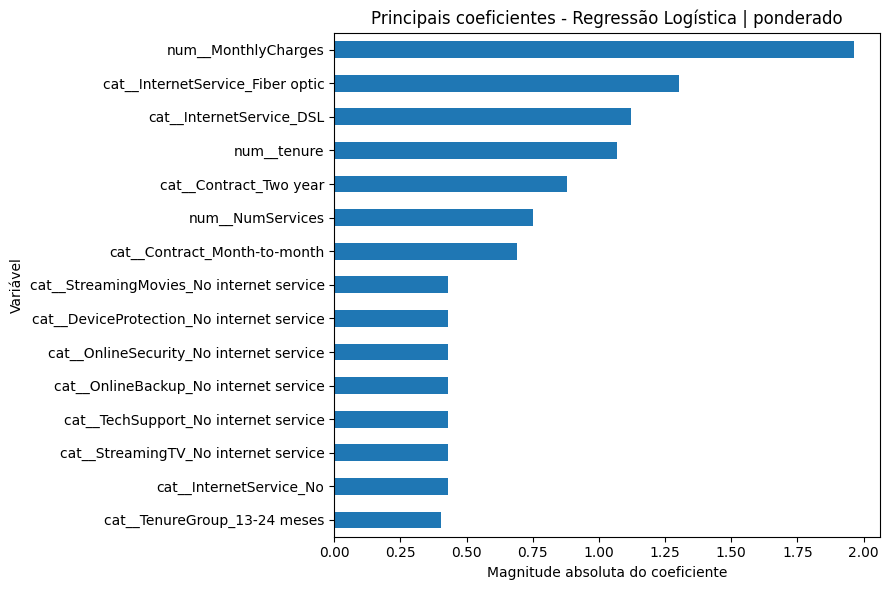

In [24]:
fitted_preprocessor = selected_pipeline.named_steps["preprocessor"]
fitted_model = selected_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

print(f"Variáveis explicativas antes do One-Hot Encoding: {X_train.shape[1]}")
print(f"Variáveis após o pré-processamento: {len(feature_names)}")

print("\nVariáveis numéricas utilizadas:")
display(pd.DataFrame({"Variável numérica": numeric_features}))

print("\nVariáveis categóricas utilizadas:")
display(pd.DataFrame({"Variável categórica": categorical_features}))

print("\nExemplo das variáveis após o pré-processamento:")
display(pd.DataFrame({"Variável transformada": feature_names}).head(30))

# Coeficientes da Regressão Logística
if hasattr(fitted_model, "coef_"):
    coeficientes = fitted_model.coef_.ravel()

    coef_df = pd.DataFrame({
        "Variável": feature_names,
        "Coeficiente": coeficientes,
        "Magnitude": np.abs(coeficientes)
    })

    coef_df["Direção"] = np.where(
        coef_df["Coeficiente"] > 0,
        "Maior associação com churn",
        "Menor associação com churn"
    )

    top_coef = (
        coef_df
        .sort_values("Magnitude", ascending=False)
        .head(15)
        .reset_index(drop=True)
    )

    print("\n15 variáveis de maior magnitude na Regressão Logística:")
    display(top_coef)

    top_plot = top_coef.sort_values("Magnitude")
    top_plot.plot(
        x="Variável",
        y="Magnitude",
        kind="barh",
        figsize=(9, 6),
        legend=False,
        title=f"Principais coeficientes - {selected_model_name}"
    )
    plt.xlabel("Magnitude absoluta do coeficiente")
    plt.tight_layout()
    plt.show()
elif hasattr(fitted_model, "feature_importances_"):
    display(pd.DataFrame({'Variável':feature_names, 'Importância por impureza':fitted_model.feature_importances_}).sort_values('Importância por impureza',ascending=False))
    print('Importâncias por impureza não indicam causalidade e podem favorecer atributos com mais possibilidades de divisão.')

<a id="secao-20"></a>

## 15. Resumo dos tratamentos realizados

| Critério | Resultado / tratamento adotado |
|---|---|
| Problema | Classificação binária de churn: prever `Cancelou` ou `Não cancelou` |
| Base | 7.043 clientes e 21 colunas originais |
| Identificação | `customerID` removido por não representar característica preditiva de negócio |
| Missing encontrado | 11 registros em `TotalCharges` |
| Tratamento do missing | Os 11 casos possuíam `tenure = 0`; `TotalCharges` foi preenchido com 0 |
| Missing após tratamento | 0 |
| Duplicidades | 0 linhas duplicadas e 0 IDs duplicados |
| Outliers | 0 outliers pelo método IQR em `tenure`, `MonthlyCharges` e `TotalCharges` |
| Alvo | `Churn`: `Yes → 1`, `No → 0` |
| Variáveis categóricas | One-Hot Encoding |
| Missing numérico no pipeline | Mediana, caso apareça novo valor ausente |
| Missing categórico no pipeline | Categoria mais frequente, caso apareça novo valor ausente |
| Engenharia de atributos | `NumServices`, `TenureGroup`, `AutomaticPayment`, `AvgMonthlySpend` |
| Avaliação da engenharia | Balanced Accuracy média: 76,54% com originais e 76,50% com originais + derivados; sem ganho demonstrado nesse experimento |
| Análise exploratória — Atividade 1 | Seis faixas nas numéricas de alta cardinalidade; taxa de churn por categoria/faixa e comparação à média global de 26,54% |
| Escalonamento | `StandardScaler` nas variáveis numéricas |
| Divisão treino/teste | 80% treino / 20% teste |
| Reprodutibilidade | `random_state = 42` |
| Estratificação | `stratify=y`, preservando aproximadamente 26,54% de churn em treino e teste |
| Algoritmos | Regressão Logística, SGD Classifier, Árvore de Decisão e Floresta Aleatória |
| Ponderação — Atividade 2 | Quatro algoritmos com `class_weight="balanced"` e controles com `class_weight=None` |
| Otimização — Atividade 3 | GridSearchCV com dois hiperparâmetros por algoritmo e cinco divisões estratificadas; comparação entre treino e validação |
| Avaliação — Atividade 4 | Accuracy, Precision, Recall e F1 de churn, Balanced Accuracy e F1 macro; matrizes absolutas e normalizadas |
| Modelo final | Regressão Logística ponderada, selecionada pela maior Balanced Accuracy média na validação: 76,60% |
| Parâmetros do modelo final | `C=10`, `fit_intercept=True`, `class_weight="balanced"` |

<a id="secao-21"></a>

## 16. Conclusão

O projeto aplicou técnicas de Machine Learning a um problema de **classificação binária de churn** em uma base com 7.043 clientes de telecomunicações.

Foram realizados:

- análise e tratamento de dados faltantes;
- análise de outliers;
- remoção de identificador sem valor preditivo de negócio;
- conversão de variáveis categóricas com One-Hot Encoding;
- engenharia de quatro novos atributos e comparação com os atributos originais;
- padronização das variáveis numéricas com StandardScaler;
- divisão estratificada entre treino e teste;
- treinamento e comparação de quatro algoritmos;
- análise da taxa de churn por categoria e por seis faixas numéricas;
- comparação de modelos com e sem ponderação de classes;
- busca de dois hiperparâmetros por algoritmo com validação cruzada;
- comparação de métricas convencionais e balanceadas.

### Resultado dos modelos

Entre os quatro algoritmos avaliados, a **Regressão Logística ponderada apresentou a maior Balanced Accuracy média na validação cruzada (76,60%)**, seguida pelo SGD ponderado (76,54%) e pela Floresta Aleatória ponderada (76,51%). Portanto, foi selecionada conforme o critério balanceado definido previamente. A proximidade das médias não demonstra superioridade estatística.

A **Regressão Logística ponderada** apresentou no conjunto de teste:

- **Accuracy: 73,31%**;
- **Precision de churn: 49,83%**;
- **Recall de churn: 78,88%**;
- **F1-score de churn: 61,08%**;
- **Balanced Accuracy: 75,09%**;
- **F1 macro: 70,39%**.

Em comparação com a versão otimizada sem ponderação, o Recall aumentou de **51,87% para 78,88%**, e a Balanced Accuracy passou de **70,96% para 75,09%**. Foram identificados **295 dos 374 cancelamentos**, contra 194 anteriormente: **101 cancelamentos adicionais identificados**. Os falsos negativos diminuíram de **180 para 79**, mas os falsos positivos aumentaram de **103 para 297**. Accuracy, Precision e F1 macro diminuíram; portanto, não houve melhoria de todas as métricas.

O SGD ponderado apresentou maior Balanced Accuracy no teste (**76,11%**), mas a escolha foi mantida com base na validação, evitando selecionar novamente após consultar o teste. A diferença treino–validação da Regressão Logística ponderada foi de aproximadamente **0,38 ponto percentual**; árvore e floresta sem ponderação apresentaram diferenças de **8,66 e 6,61 pontos percentuais**, indicando maior sobreajuste nesses cenários.

A análise exploratória identificou taxas de churn de **47,44%** para clientes com até 12 meses de permanência e **42,71%** para contratos mensais, superiores à média global de **26,54%**. A comparação dos atributos originais com os originais e derivados obteve Balanced Accuracy média de **76,54% e 76,50%**, respectivamente, sem ganho demonstrado com a engenharia nesse experimento.

### Benefício para o negócio

O modelo pode apoiar áreas de retenção, CRM, marketing e atendimento na priorização de clientes com maior risco de cancelamento, permitindo direcionar:

- ofertas personalizadas;
- renegociação ou alteração de planos;
- contato preventivo;
- suporte direcionado;
- campanhas de fidelização.

A maior identificação de churn é acompanhada de mais falsos alertas e maior demanda operacional. Sem estimativas dos custos das abordagens e da efetividade das intervenções, não se afirma superioridade econômica do modelo ponderado.

O modelo deve ser entendido como uma ferramenta de **apoio à decisão**: ele identifica padrões associados ao churn, mas não demonstra causalidade entre uma característica isolada e o cancelamento. 

### Limitação temporal e aplicação futura

O experimento avalia a capacidade de classificar o churn registrado na base a partir das características disponíveis dos clientes. Como não foi definida uma data de referência para a coleta dos atributos nem uma janela futura de cancelamento, os resultados não demonstram, por si só, capacidade de antecipar o churn com determinada antecedência.

Para uma aplicação preventiva, seria necessário definir, por exemplo, a previsão de cancelamento nos próximos 30 dias, utilizando exclusivamente informações disponíveis antes do início desse período. A avaliação deveria considerar dados de períodos posteriores aos utilizados no treinamento. Essa limitação não invalida a comparação atual que foi realizada, mas delimita a interpretação dos resultados e os requisitos para uma aplicação operacional.

<a id="secao-22"></a>

## 17. Da atividade:

### 1. Qual problema será resolvido? O que está sendo previsto e quem se beneficia?

O projeto busca **classificar clientes de uma empresa de telecomunicações quanto ao risco de cancelamento**. A variável prevista é `Churn`, transformada em `0 = não cancelou` e `1 = cancelou`.

Beneficiários: áreas de **retenção, CRM, marketing, relacionamento e atendimento**.

---

### 2. Há missing ou outliers? Como foram tratados?

**Missing:** foram encontrados 11 valores ausentes em `TotalCharges`. Todos pertenciam a clientes com `tenure = 0`; portanto, `TotalCharges` foi preenchido com 0. Após o tratamento, não restaram missings.

**Outliers:** pelo método IQR, não foram detectados outliers em `tenure`, `MonthlyCharges` ou `TotalCharges`.

**Duplicidades:** não foram encontradas linhas duplicadas nem IDs duplicados.

---

### 3. Como as variáveis textuais foram convertidas em numéricas?

- `Churn`: `No → 0` e `Yes → 1`;
- demais variáveis categóricas: **One-Hot Encoding**, criando colunas binárias 0/1 para cada categoria.

---

### 4. Quais técnicas de engenharia de variáveis foram testadas?

Foram criadas:

- `NumServices`: agregação de serviços contratados;
- `TenureGroup`: discretização do tempo de relacionamento;
- `AutomaticPayment`: indicador de pagamento automático;
- `AvgMonthlySpend`: razão entre cobrança acumulada e tempo de relacionamento, com regra para clientes novos.

A comparação com Regressão Logística ponderada e as mesmas divisões de validação obteve **76,54%** de Balanced Accuracy média com atributos originais e **76,50%** com originais + derivados. Não foi demonstrado ganho nessa configuração.

Na **Atividade 1**, numéricas com muitos valores distintos foram segmentadas em **seis faixas** para análise descritiva. Para todas as explicativas, foram apresentados tamanho do grupo, quantidade de churns, taxa de churn e diferença para a média global de **26,54%**. As faixas exploratórias não foram adicionadas automaticamente aos modelos.

---

### 5. Qual técnica de escalonamento foi usada?

Foi utilizado **StandardScaler** nas variáveis numéricas, dentro do pipeline de pré-processamento, ajustado no treino em cada divisão da validação.

---

### 6. Quais algoritmos de classificação foram comparados?

Foram avaliados:

- Regressão Logística;
- SGD Classifier;
- Árvore de Decisão;
- Floresta Aleatória.

As métricas calculadas foram **Accuracy, Precision, Recall e F1-score de churn**, complementadas por **Balanced Accuracy e F1 macro**.

Na **Atividade 2**, cada algoritmo foi treinado com `class_weight="balanced"` e comparado a um controle sem ponderação. Na **Atividade 3**, o GridSearchCV testou dois hiperparâmetros por algoritmo, com cinco divisões estratificadas: `C` e `fit_intercept`; `alpha` e `penalty`; e, para árvore e floresta, `max_depth` e `min_samples_leaf`. Foram examinados o desempenho de treino, a média e o desvio da validação para investigar sobreajuste.

---

### 7. Qual foi o melhor algoritmo e qual modelo foi selecionado?

Na **Atividade 4**, a escolha seguiu a **maior Balanced Accuracy média na validação cruzada**. A **Regressão Logística ponderada** obteve **76,60%**, sendo selecionada com `C=10`, `fit_intercept=True` e `class_weight="balanced"`.

No conjunto de teste, apresentou:

- **Accuracy: 73,31%**;
- **Precision: 49,83%**;
- **Recall: 78,88%**;
- **F1-score: 61,08%**;
- **Balanced Accuracy: 75,09%**;
- **F1 macro: 70,39%**.

A versão sem ponderação apresentou Balanced Accuracy de **70,96%** e Recall de **51,87%**. A versão ponderada identificou **101 cancelamentos adicionais**, com **194 falsos alertas adicionais**. O SGD ponderado obteve maior Balanced Accuracy no teste (**76,11%**), mas a seleção foi mantida conforme a validação. As pequenas diferenças entre as médias de validação não comprovam superioridade estatística.

---

### 8. Quais variáveis foram utilizadas no treinamento?

Após a remoção de `customerID` e a criação dos novos atributos, foram utilizadas **23 variáveis explicativas antes da codificação**:

**Numéricas:**
`SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`, `NumServices`, `AvgMonthlySpend`.

**Categóricas:**
`gender`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaperlessBilling`, `PaymentMethod`, `TenureGroup`, `AutomaticPayment`.

Após o One-Hot Encoding, essas variáveis resultaram em **53 atributos transformados** utilizados pelo modelo.

In [25]:
display(Markdown(f'**Resultado selecionado na validação:** {selected_model_name}.'))
display(results_df[results_df['Modelo'].eq(selected_model_name)])

**Resultado selecionado na validação:** Regressão Logística | ponderado.

,Modelo,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,F1 macro
1,Regressão Logística | ponderado,0.7331,0.7509,0.4983,0.7888,0.6108,0.7039
